**Cell 00 · Cell index** — each cell is prefixed with `Cell NN · name` (also in cell metadata `cell_label`).

- **01 · Intro**
- **02 · Imports & dataset config**
- **03 · Data helpers code**
- **04 · Modeling notes**
- **05 · Rule-base overview**
- **06 · Rule-base portfolio statistics**
- **07 · d_dose overview**
- **08 · d_dose load & preview**
- **09 · d_dose encode & column overview**
- **10 · d_dose unified summary**
- **11 · d_dose summary plots**
- **12 · s_dose overview**
- **13 · s_dose load & preview**
- **14 · s_dose encode & column overview**
- **15 · s_dose unified summary**
- **16 · s_dose summary plots**
- **17 · r_dose overview**
- **18 · r_dose load & preview**
- **19 · r_dose encode & column overview**
- **20 · r_dose unified summary**
- **21 · r_dose summary plots**
- **22 · preg_risk overview**
- **23 · preg_risk load & preview**
- **24 · preg_risk encode & column overview**
- **25 · preg_risk unified summary**
- **26 · preg_risk summary plots**
- **27 · generic_disease_map overview**
- **28 · generic_disease_map load & preview**
- **29 · generic_disease_map encode & column overview**
- **30 · generic_disease_map unified summary**
- **31 · generic_disease_map summary plots**
- **32 · Lift by condition overview**
- **33 · Lift by condition tables**
- **34 · Confidence by condition overview**
- **35 · Confidence by condition tables**
- **36 · Practitioner query overview**
- **37 · Practitioner query demo**
- **38 · Renal & pregnancy overview**
- **39 · Renal & pregnancy demo**


**Cell 01 · Intro**

# DOSAGE — Descriptive Statistics

Unified summary of the DOSAGE antibiotic dosing files:

- `d_dose.csv` — disease-specific regimens
- `s_dose.csv` — standardized regimens
- `r_dose.csv` — renal adjustments
- `preg_risk.csv` — FDA pregnancy risk categories
- `generic_disease_map.csv` — antibiotic–disease lookup

These tables are mostly **ratio** numeric fields (dose, age, weight, CrCl ranges) with a few **nominal** identifiers (`generic`, `disease`) and low-cardinality fields (`route`, `flag`). Each row is a **clinical dosing rule** (antecedent conditions → consequent dose range), not a patient record.

The notebook includes:
1. **Rule-base descriptive statistics** — coverage, rule counts, regimen types, structured missingness
2. **Per-file analysis** — raw preview, one-hot encoding, unified summary table, summary plots
3. **Modeling notes** — how these tables fit together for lookup / CDSS (saved for later)
4. **Lift by condition** — top rule-set lifts for the most common `d_dose` diseases
5. **Confidence by condition** — top rule-set confidence P(S|D) for the most common `d_dose` diseases
6. **Practitioner query demo** — five random patient + condition vignettes with consequent dosage and support / confidence / lift (Cells **36–37**)


In [54]:
# Cell 02 · Imports & dataset config
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

DATA_DIR = Path(".")

DATASETS = {
    "d_dose": DATA_DIR / "d_dose.csv",
    "s_dose": DATA_DIR / "s_dose.csv",
    "r_dose": DATA_DIR / "r_dose.csv",
    "preg_risk": DATA_DIR / "preg_risk.csv",
    "generic_disease_map": DATA_DIR / "generic_disease_map.csv",
}

PREG_CATEGORY_ORDER = ["A", "B", "C", "D", "X"]
PREG_CATEGORY_ORDINAL = {cat: i for i, cat in enumerate(PREG_CATEGORY_ORDER)}
ROUTE_ORDER = ["PO", "IV", "IM"]

ENCODING_CONFIG = {
    "d_dose": {"one_hot": ["route"], "ordinal": {}, "overview": ["generic", "disease", "route"]},
    "s_dose": {"one_hot": ["route"], "ordinal": {}, "overview": ["generic", "route"]},
    "r_dose": {"one_hot": ["route", "flag"], "ordinal": {}, "overview": ["generic", "disease", "route"]},
    "preg_risk": {
        "one_hot": [],
        "ordinal": {"r_category": PREG_CATEGORY_ORDINAL},
        "overview": ["generic", "r_category"],
    },
    "generic_disease_map": {"one_hot": [], "ordinal": {}, "overview": ["generic", "disease"]},
}


In [55]:
# Cell 03 · Data helpers code
def load_dataset(path: Path) -> pd.DataFrame:
    df_raw = pd.read_csv(path)
    print(f"{path.name}: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
    return df_raw


def clean_dataset(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    drop_cols = [
        c
        for c in df.columns
        if c.startswith("Unnamed") or df[c].isna().all()
    ]
    return df.drop(columns=drop_cols, errors="ignore")


def encode_dataset(df_raw: pd.DataFrame, dataset_key: str) -> pd.DataFrame:
    cfg = ENCODING_CONFIG[dataset_key]
    df = df_raw.copy()

    one_hot_cols = [c for c in cfg["one_hot"] if c in df.columns]
    if one_hot_cols:
        df = pd.get_dummies(df, columns=one_hot_cols, dtype=int)

    for col, mapping in cfg["ordinal"].items():
        if col in df.columns:
            df[f"{col}_ordinal"] = df[col].map(mapping)
            df = df.drop(columns=[col])

    print(f"Analysis shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
    return df


def infer_measurement_level(col: str) -> str:
    if col.startswith(("route_", "flag_")):
        return "nominal (binary indicator)"
    if col.endswith("_ordinal"):
        return "ordinal"
    if col in {"generic", "disease"}:
        return "nominal"
    if any(token in col for token in ("age", "weight", "dose", "crcl", "limit")):
        return "ratio"
    return "nominal"


def build_measurement_levels(df: pd.DataFrame) -> dict[str, str]:
    return {col: infer_measurement_level(col) for col in df.columns}


def build_column_overview(df_raw: pd.DataFrame, dataset_key: str) -> pd.DataFrame:
    overview_cols = ENCODING_CONFIG[dataset_key]["overview"]
    rows = []
    for col in overview_cols:
        if col not in df_raw.columns:
            continue
        level = "ordinal" if col == "r_category" else infer_measurement_level(col)
        rows.append(
            {
                "column": col,
                "unique_values": int(df_raw[col].nunique(dropna=True)),
                "measurement_level": level,
            }
        )
    return pd.DataFrame(rows).set_index("column")


def column_mode(series: pd.Series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if len(modes) else np.nan


def iqr_outlier_count(series: pd.Series) -> int:
    values = pd.to_numeric(series, errors="coerce").dropna()
    if len(values) < 4:
        return 0
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        return 0
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((values < lower) | (values > upper)).sum())


def build_unified_summary(df: pd.DataFrame, measurement_levels: dict[str, str]) -> pd.DataFrame:
    rows = []
    for col in df.columns:
        s = df[col]
        is_numeric = pd.api.types.is_numeric_dtype(s)
        level = measurement_levels[col]
        distribution_stats = level in {"interval", "ratio", "ordinal"}
        numeric = pd.to_numeric(s, errors="coerce") if is_numeric else pd.Series(dtype=float)

        rows.append(
            {
                "column": col,
                "data_type": str(s.dtype),
                "measurement_level": level,
                "count": int(s.count()),
                "missing": int(s.isna().sum()),
                "unique_values": int(s.nunique()),
                "mean": numeric.mean() if is_numeric and numeric.notna().any() else np.nan,
                "median": numeric.median() if is_numeric and numeric.notna().any() else np.nan,
                "mode": column_mode(s),
                "min": numeric.min() if is_numeric and numeric.notna().any() else np.nan,
                "max": numeric.max() if is_numeric and numeric.notna().any() else np.nan,
                "range": (numeric.max() - numeric.min())
                if is_numeric and numeric.notna().any()
                else np.nan,
                "skew": stats.skew(numeric.dropna(), bias=False)
                if distribution_stats and numeric.notna().sum() >= 3
                else np.nan,
                "iqr_outlier_count": iqr_outlier_count(numeric)
                if distribution_stats
                else np.nan,
            }
        )

    summary = pd.DataFrame(rows).set_index("column")
    for c in ["mean", "median", "min", "max", "range", "skew"]:
        summary[c] = summary[c].round(3)
    summary["iqr_outlier_count"] = summary["iqr_outlier_count"].astype("Int64")
    return summary


def top_counts_with_other(series: pd.Series, top_n: int = 5) -> pd.Series:
    counts = series.dropna().value_counts()
    top = counts.head(top_n)
    other = int(counts.iloc[top_n:].sum())
    if other > 0:
        top = pd.concat([top, pd.Series({"Other": other})])
    return top


def label_bars_with_headroom(ax, bars, padding=3, headroom=0.12) -> None:
    ax.bar_label(bars, padding=padding)
    _, ymax = ax.get_ylim()
    if ymax > 0:
        ax.set_ylim(top=ymax * (1 + headroom))
    ax.margins(y=0.05)


def plot_top_category_bar(ax, series: pd.Series, title: str, xlabel: str, color: str) -> None:
    counts = top_counts_with_other(series)
    bars = ax.bar(counts.index.astype(str), counts.values, color=color, edgecolor="white")
    ax.set_title(title, pad=12)
    ax.set_xlabel(xlabel, labelpad=10)
    ax.set_ylabel("Count")
    label_bars_with_headroom(ax, bars)
    ax.tick_params(axis="x", rotation=25, pad=8)


def plot_numeric_hist(ax, series: pd.Series, title: str, xlabel: str, color: str, bins: int = 20) -> None:
    values = pd.to_numeric(series, errors="coerce").dropna()
    if values.empty:
        ax.text(0.5, 0.5, "No non-null values", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title, pad=12)
        return
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set_title(title, pad=12)
    ax.set_xlabel(xlabel, labelpad=10)
    ax.set_ylabel("Frequency")


def plot_route_bar(ax, df_raw: pd.DataFrame) -> None:
    if "route" not in df_raw.columns:
        ax.axis("off")
        return
    route_counts = (
        df_raw["route"].dropna().value_counts().reindex(ROUTE_ORDER, fill_value=0)
    )
    bars = ax.bar(route_counts.index, route_counts.values, color="#4C72B0", edgecolor="white")
    ax.set_title("Administration Route", pad=12)
    ax.set_xlabel("Route", labelpad=10)
    ax.set_ylabel("Count")
    label_bars_with_headroom(ax, bars)


def plot_dosage_summary(df_raw: pd.DataFrame, dataset_key: str, title: str) -> None:
    fig = plt.figure(figsize=(14, 13.5))
    grid = fig.add_gridspec(3, 2, height_ratios=[1.1, 1, 1], hspace=0.55, wspace=0.28)

    if dataset_key in {"d_dose", "s_dose"}:
        ax_route = fig.add_subplot(grid[0, :])
        plot_route_bar(ax_route, df_raw)

        ax_generic = fig.add_subplot(grid[1, 0])
        plot_top_category_bar(ax_generic, df_raw["generic"], "Top Antibiotics — generic", "Antibiotic", "#E15759")

        ax_dose = fig.add_subplot(grid[1, 1])
        plot_numeric_hist(ax_dose, df_raw["max_dose_dw_mg"], "Max Weight-Based Dose (mg/kg/day)", "max_dose_dw_mg", "#59A14F")

        ax_age = fig.add_subplot(grid[2, 0])
        plot_numeric_hist(ax_age, df_raw["max_age_y"], "Max Age (years)", "max_age_y", "#F28E2B")

        ax_weight = fig.add_subplot(grid[2, 1])
        plot_numeric_hist(ax_weight, df_raw["max_weight"], "Max Weight (kg)", "max_weight", "#B07AA1")

    elif dataset_key == "r_dose":
        ax_route = fig.add_subplot(grid[0, :])
        plot_route_bar(ax_route, df_raw)

        ax_generic = fig.add_subplot(grid[1, 0])
        plot_top_category_bar(ax_generic, df_raw["generic"], "Top Antibiotics — generic", "Antibiotic", "#E15759")

        ax_crcl = fig.add_subplot(grid[1, 1])
        plot_numeric_hist(ax_crcl, df_raw["max_crcl"], "Max CrCl (mL/min)", "max_crcl", "#59A14F")

        ax_dose = fig.add_subplot(grid[2, 0])
        plot_numeric_hist(ax_dose, df_raw["max_dose_dw_mg"], "Max Weight-Based Dose (mg/kg/day)", "max_dose_dw_mg", "#F28E2B")

        ax_dd = fig.add_subplot(grid[2, 1])
        plot_numeric_hist(ax_dd, df_raw["max_dose_dd_mg"], "Max Direct Daily Dose (mg)", "max_dose_dd_mg", "#B07AA1")

    elif dataset_key == "preg_risk":
        preg_counts = (
            df_raw["r_category"].value_counts().reindex(PREG_CATEGORY_ORDER, fill_value=0)
        )
        ax_preg = fig.add_subplot(grid[0, :])
        bars = ax_preg.bar(preg_counts.index, preg_counts.values, color="#4C72B0", edgecolor="white")
        ax_preg.set_title("FDA Pregnancy Risk Category", pad=12)
        ax_preg.set_xlabel("Category", labelpad=10)
        ax_preg.set_ylabel("Count")
        label_bars_with_headroom(ax_preg, bars)

        ax_generic = fig.add_subplot(grid[1, :])
        plot_top_category_bar(ax_generic, df_raw["generic"], "Top Antibiotics — generic", "Antibiotic", "#E15759")

        ordinal_counts = df_raw["r_category"].map(PREG_CATEGORY_ORDINAL).value_counts().sort_index()
        ax_ord = fig.add_subplot(grid[2, :])
        bars = ax_ord.bar(ordinal_counts.index, ordinal_counts.values, color="#59A14F", edgecolor="white", width=0.8)
        ax_ord.set_title("Pregnancy Risk (ordinal: A=0 … X=4)", pad=12)
        ax_ord.set_xlabel("Ordinal code", labelpad=10)
        ax_ord.set_ylabel("Frequency")
        ax_ord.set_xticks(list(PREG_CATEGORY_ORDINAL.values()))
        label_bars_with_headroom(ax_ord, bars)

    else:  # generic_disease_map
        ax_generic = fig.add_subplot(grid[0, :])
        plot_top_category_bar(ax_generic, df_raw["generic"], "Top Antibiotics — generic", "Antibiotic", "#E15759")

        ax_disease = fig.add_subplot(grid[1, :])
        plot_top_category_bar(ax_disease, df_raw["disease"], "Top Diseases — disease", "Disease", "#4C72B0")

        ax_pairs = fig.add_subplot(grid[2, :])
        pair_counts = df_raw.groupby("generic")["disease"].nunique().sort_values(ascending=False).head(10)
        bars = ax_pairs.bar(pair_counts.index.astype(str), pair_counts.values, color="#59A14F", edgecolor="white")
        ax_pairs.set_title("Top 10 Antibiotics by Disease Coverage", pad=12)
        ax_pairs.set_xlabel("Antibiotic", labelpad=10)
        ax_pairs.set_ylabel("Unique diseases")
        label_bars_with_headroom(ax_pairs, bars)
        ax_pairs.tick_params(axis="x", rotation=25, pad=8)

    fig.suptitle(title, fontsize=14, y=0.98)
    fig.subplots_adjust(top=0.90, hspace=0.78, wspace=0.28, bottom=0.11)
    plt.show()


AGE_DAY_COLS = ["min_age_d", "max_age_d"]
AGE_MONTH_COLS = ["min_age_m", "max_age_m"]
AGE_YEAR_COLS = ["min_age_y", "max_age_y"]
DOSE_DW_COLS = ["min_dose_dw_mg", "max_dose_dw_mg"]
DOSE_DD_COLS = ["min_dose_dd_mg", "max_dose_dd_mg"]


def _row_has_any(row: pd.Series, cols: list[str]) -> bool:
    return any(pd.notna(row.get(c)) for c in cols if c in row.index)


def age_unit_label(row: pd.Series) -> str:
    units = []
    if _row_has_any(row, AGE_DAY_COLS):
        units.append("days")
    if _row_has_any(row, AGE_MONTH_COLS):
        units.append("months")
    if _row_has_any(row, AGE_YEAR_COLS):
        units.append("years")
    return "+".join(units) if units else "none"


def dose_regimen_label(row: pd.Series) -> str:
    has_dw = _row_has_any(row, DOSE_DW_COLS)
    has_dd = _row_has_any(row, DOSE_DD_COLS)
    if has_dw and has_dd:
        return "both_dw_dd"
    if has_dw:
        return "weight_based_dw"
    if has_dd:
        return "direct_daily_dd"
    return "unspecified"


def pct(n: int, denom: int) -> float:
    return round(100 * n / denom, 1) if denom else 0.0


def build_rule_profile(df_raw: pd.DataFrame, dataset_key: str) -> pd.DataFrame:
    """Rule-base stats tailored to each DOSAGE table."""
    n = len(df_raw)
    rows: list[dict] = []

    def add(metric: str, value) -> None:
        rows.append({"metric": metric, "value": value})

    add("rule_rows", f"{n:,}")
    if "generic" in df_raw.columns:
        add("unique_generics", int(df_raw["generic"].nunique()))
        rules_per_generic = df_raw.groupby("generic").size()
        add("rules_per_generic (median)", float(rules_per_generic.median()))
        add("rules_per_generic (max)", int(rules_per_generic.max()))

    if dataset_key == "d_dose":
        add("unique_diseases", int(df_raw["disease"].nunique(dropna=True)))
        pair_counts = df_raw.groupby(["generic", "disease"]).size()
        add("rules_per_generic+disease (median)", float(pair_counts.median()))
        add("duplicate rows on generic+disease+route", int(df_raw.duplicated(subset=["generic", "disease", "route"]).sum()))

        regimen = df_raw.apply(dose_regimen_label, axis=1).value_counts()
        for label in ["weight_based_dw", "direct_daily_dd", "both_dw_dd", "unspecified"]:
            add(f"regimen — {label} (%)", pct(int(regimen.get(label, 0)), n))

        age_units = df_raw.apply(age_unit_label, axis=1).value_counts()
        for label, count in age_units.items():
            add(f"age band unit — {label} (%)", pct(int(count), n))

        has_dw = df_raw.apply(lambda r: dose_regimen_label(r) in {"weight_based_dw", "both_dw_dd"}, axis=1)
        has_weight_band = df_raw["min_weight"].notna() | df_raw["max_weight"].notna()
        add("rows with weight band (all rules, %)", pct(int(has_weight_band.sum()), n))
        add("weight-based rules with weight band (%)", pct(int((has_dw & has_weight_band).sum()), int(has_dw.sum())))

    elif dataset_key == "s_dose":
        regimen = df_raw.apply(dose_regimen_label, axis=1).value_counts()
        for label in ["weight_based_dw", "direct_daily_dd", "both_dw_dd", "unspecified"]:
            add(f"regimen — {label} (%)", pct(int(regimen.get(label, 0)), n))

        age_units = df_raw.apply(age_unit_label, axis=1).value_counts()
        for label, count in age_units.items():
            add(f"age band unit — {label} (%)", pct(int(count), n))

        has_weight_band = df_raw["min_weight"].notna() | df_raw["max_weight"].notna()
        add("rows with weight band (%)", pct(int(has_weight_band.sum()), n))

    elif dataset_key == "r_dose":
        add("rows with disease populated", int(df_raw["disease"].notna().sum()))
        add("rows with renal flag", int(df_raw["flag"].notna().sum()))
        crcl_per_generic = df_raw.groupby("generic").size()
        add("CrCl rules per generic (median)", float(crcl_per_generic.median()))
        add("CrCl rules per generic (max)", int(crcl_per_generic.max()))

    elif dataset_key == "preg_risk":
        add("unique pregnancy categories", int(df_raw["r_category"].nunique()))
        for cat in PREG_CATEGORY_ORDER:
            add(f"category {cat} (%)", pct(int((df_raw["r_category"] == cat).sum()), n))

    elif dataset_key == "generic_disease_map":
        diseases_per_generic = df_raw.groupby("generic")["disease"].nunique()
        add("disease links per generic (median)", float(diseases_per_generic.median()))
        add("disease links per generic (max)", int(diseases_per_generic.max()))

    return pd.DataFrame(rows).set_index("metric")


def build_structured_missingness(df_raw: pd.DataFrame, dataset_key: str) -> pd.DataFrame:
    """Explain why age/weight columns look sparse — parallel scales, not random gaps."""
    if dataset_key not in {"d_dose", "s_dose", "r_dose"}:
        return pd.DataFrame()

    cols = [c for c in df_raw.columns if any(tok in c for tok in ("age", "weight", "crcl"))]
    rows = []
    for col in cols:
        miss_pct = pct(int(df_raw[col].isna().sum()), len(df_raw))
        note = ""
        if "age_d" in col:
            note = "Often blank when rule uses months/years"
        elif "age_m" in col:
            note = "Often blank when rule uses days/years"
        elif "age_y" in col:
            note = "Often blank when rule uses days/months only"
        elif "weight" in col:
            note = "Only populated for weight-stratified bands"
        elif "crcl" in col:
            note = "Core antecedent for renal rules"
        rows.append({"column": col, "missing_pct": miss_pct, "note": note})

    out = pd.DataFrame(rows).set_index("column")
    return out.sort_values("missing_pct", ascending=False)


def build_cross_table_coverage(
    d_dose: pd.DataFrame,
    s_dose: pd.DataFrame,
    r_dose: pd.DataFrame,
    preg_risk: pd.DataFrame,
    generic_map: pd.DataFrame,
) -> pd.DataFrame:
    """How antibiotics link across rule tables (not row-index joins)."""
    d_gen = set(d_dose["generic"].unique())
    s_gen = set(s_dose["generic"].unique())
    r_gen = set(r_dose["generic"].unique())
    p_gen = set(preg_risk["generic"].unique())
    m_gen = set(generic_map["generic"].unique())

    rows = [
        {"metric": "generics in d_dose", "count": len(d_gen)},
        {"metric": "generics in s_dose", "count": len(s_gen)},
        {"metric": "generics in r_dose", "count": len(r_gen)},
        {"metric": "generics in preg_risk", "count": len(p_gen)},
        {"metric": "generics in disease map", "count": len(m_gen)},
        {"metric": "d_dose and s_dose overlap (standard fallback available)", "count": len(d_gen & s_gen)},
        {"metric": "d_dose and r_dose overlap (renal layer available)", "count": len(d_gen & r_gen)},
        {"metric": "d_dose and preg_risk overlap", "count": len(d_gen & p_gen)},
        {"metric": "d_dose only (no s_dose fallback)", "count": len(d_gen - s_gen)},
        {"metric": "d_dose without renal rules", "count": len(d_gen - r_gen)},
        {"metric": "disease map pairs", "count": len(generic_map.dropna(subset=["generic", "disease"]))},
    ]
    return pd.DataFrame(rows).set_index("metric")


**Cell 04 · Modeling notes**

## Modeling notes (for later)

These tables are a **compiled clinical rule base**, not patient-level training data. Each row is one guideline slice:

```
IF generic = X AND disease = Y AND route = Z AND age ∈ [min, max] …
THEN dose range (min_dose_*, max_dose_*)
```

### Association-rule analogy

| Concept | DOSAGE equivalent |
|---------|-------------------|
| Antecedent (conditions) | `generic`, `disease`, `route`, age/weight/CrCl **bands** |
| Consequent (outcome) | Dose interval (`min_*`, `max_*`, caps) |
| Query | Enter patient facts → **filter** matching rule row(s) |

This resembles **forward chaining** or a **decision table**, not FP-Growth mining. Rules are **authored**, not discovered from transactions. FP-Growth is the wrong *tool*, but the right *mental model* for usage.

### Can the files be merged into one ML table?

**Not cleanly.** There is no shared row index or primary key. Tables link on clinical dimensions (`generic`, `route`, optional `disease`, numeric **ranges**). Blind SQL joins inflate rows (many CrCl bands × many age bands per drug).

Intended combination is **layered lookup**:

1. **`d_dose`** — disease-specific regimen (filter by generic, disease, age, route)
2. **`s_dose`** — fallback when no disease-specific rule applies
3. **`r_dose`** — renal cap/override by CrCl band (mostly `generic + route`, disease rarely populated)
4. **`preg_risk`** — attach pregnancy category 1:1 on `generic`
5. **`generic_disease_map`** — valid generic–disease pairs for lookup validation

### Why age/weight look "missing"

- **Age**: three parallel scales (`_d`, `_m`, `_y`). A row uses the scale matching its band — blank `min_age_d` usually means the rule is expressed in **years**, not unknown age.
- **Weight**: only populated when the guideline stratifies by weight. Most weight-based (`dw`) rules leave weight blank because mg/kg/day is applied using the patient's actual weight at prescribing time.
- **Direct daily dose (`dd`)** rows often omit weight entirely.

### Modeling directions to revisit

| Approach | Role of these tables |
|----------|---------------------|
| **Rule engine / CDSS** | Primary use case — filter → match → return dose interval |
| **Retrieval + interpolation** | Lookup rule, optionally midpoint of min/max |
| **ML on rules themselves** | Each rule row as a labeled example (conditions → dose range) — learns the guideline surface, not real prescribing |
| **ML on external EHR data** | DOSAGE as reference layer for audit, anomaly detection, or label generation |

**Conflict resolution** when multiple rows match: prefer the **most specific** band (narrowest age/CrCl range), `d_dose` before `s_dose`, then apply `r_dose` caps.


**Cell 05 · Rule-base overview**

## Rule-base descriptive statistics

Column-level summaries treat every field independently; these metrics describe **rule structure** — how many guidelines exist, how antecedents are expressed, and how tables connect across antibiotics.


In [56]:
# Cell 06 · Rule-base portfolio statistics
# Load all tables once for portfolio-level rule statistics
_tables = {
    key: clean_dataset(load_dataset(path))
    for key, path in DATASETS.items()
}

cross_table_coverage = build_cross_table_coverage(
    _tables["d_dose"],
    _tables["s_dose"],
    _tables["r_dose"],
    _tables["preg_risk"],
    _tables["generic_disease_map"],
)
print("=== Cross-table antibiotic coverage ===")
display(cross_table_coverage)

for key in ["d_dose", "s_dose", "r_dose", "preg_risk", "generic_disease_map"]:
    print(f"\n=== Rule profile — {key} ===")
    display(build_rule_profile(_tables[key], key))

for key in ["d_dose", "s_dose", "r_dose"]:
    print(f"\n=== Structured missingness — {key} ===")
    display(build_structured_missingness(_tables[key], key))


d_dose.csv: 3,029 rows × 22 columns
s_dose.csv: 288 rows × 20 columns
r_dose.csv: 220 rows × 12 columns
preg_risk.csv: 98 rows × 2 columns
generic_disease_map.csv: 1,066 rows × 2 columns
=== Cross-table antibiotic coverage ===


,count
metric,
generics in d_dose,97
generics in s_dose,89
generics in r_dose,73
generics in preg_risk,97
generics in disease map,97
d_dose and s_dose overlap (standard fallback available),88
d_dose and r_dose overlap (renal layer available),70
d_dose and preg_risk overlap,92
d_dose only (no s_dose fallback),9



=== Rule profile — d_dose ===


,value
metric,
rule_rows,"3,029"
unique_generics,97
rules_per_generic (median),14.0
rules_per_generic (max),198
unique_diseases,267
rules_per_generic+disease (median),2.0
duplicate rows on generic+disease+route,1476
regimen — weight_based_dw (%),44.1
regimen — direct_daily_dd (%),54.8



=== Rule profile — s_dose ===


,value
metric,
rule_rows,288
unique_generics,89
rules_per_generic (median),2.0
rules_per_generic (max),16
regimen — weight_based_dw (%),49.7
regimen — direct_daily_dd (%),47.9
regimen — both_dw_dd (%),0.3
regimen — unspecified (%),2.1
age band unit — years (%),51.7


... (8 outputs left out)


=== Structured missingness — s_dose ===


,missing_pct,note
column,,
max_age_m,99.3,Often blank when rule uses days/years
max_weight,95.1,Only populated for weight-stratified bands
min_weight,94.4,Only populated for weight-stratified bands
max_age_d,87.5,Often blank when rule uses months/years
min_age_d,84.7,Often blank when rule uses months/years
min_age_m,67.0,Often blank when rule uses days/years
min_age_y,48.3,Often blank when rule uses days/months only
max_age_y,13.2,Often blank when rule uses days/months only



=== Structured missingness — r_dose ===


,missing_pct,note
column,,
max_weight,88.6,Only populated for weight-stratified bands
min_weight,86.4,Only populated for weight-stratified bands
max_crcl,10.5,Core antecedent for renal rules
min_crcl,10.0,Core antecedent for renal rules


**Cell 07 · d_dose overview**

Disease-specific dosing regimens. Raw preview first, then one-hot encoding of low-cardinality fields (where applicable), unified summary, and summary plots.


In [57]:
# Cell 08 · d_dose load & preview
df_raw_d_dose = clean_dataset(load_dataset(DATASETS["d_dose"]))
df_raw_d_dose.head()


d_dose.csv: 3,029 rows × 22 columns


,generic,disease,min_age_d,max_age_d,min_age_m,max_age_m,min_age_y,max_age_y,min_weight,max_weight,...,max_dose_dw_mg,min_dose_dw_iu,max_dose_dw_iu,limit_mg,limit_iu,min_dose_dd_mg,max_dose_dd_mg,min_dose_dd_UNIT,max_dose_dd_iu,route
0,Amikacin,Bacteremia,NaN,NaN,NaN,NaN,12.0,65.0,NaN,NaN,...,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IM
1,Amikacin,Bacteremia,NaN,NaN,NaN,NaN,12.0,65.0,NaN,NaN,...,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IV
2,Amikacin,Bacteremia,NaN,NaN,NaN,NaN,65.0,120.0,NaN,NaN,...,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IM
3,Amikacin,Bacteremia,NaN,NaN,NaN,NaN,65.0,120.0,NaN,NaN,...,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IM
4,Amikacin,Bacteremia,NaN,NaN,NaN,NaN,65.0,120.0,NaN,NaN,...,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IV


In [58]:
# Cell 09 · d_dose encode & column overview
df_d_dose = encode_dataset(df_raw_d_dose, "d_dose")
measurement_levels_d_dose = build_measurement_levels(df_d_dose)
column_overview_d_dose = build_column_overview(df_raw_d_dose, "d_dose")
column_overview_d_dose


Analysis shape: 3,029 rows × 23 columns


,unique_values,measurement_level
column,,
generic,97,nominal
disease,267,nominal
route,3,nominal


In [59]:
# Cell 10 · d_dose unified summary
unified_summary_d_dose = build_unified_summary(df_d_dose, measurement_levels_d_dose)
unified_summary_d_dose


C:\Users\tnewman\AppData\Local\Temp\ipykernel_38796\3545277948.py:110: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  "skew": stats.skew(numeric.dropna(), bias=False)
C:\Users\tnewman\AppData\Local\Temp\ipykernel_38796\3545277948.py:110: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  "skew": stats.skew(numeric.dropna(), bias=False)


,data_type,measurement_level,count,missing,unique_values,mean,median,mode,min,max,range,skew,iqr_outlier_count
column,,,,,,,,,,,,,
generic,str,nominal,3029,0,97,NaN,NaN,Flucloxacillin,NaN,NaN,NaN,NaN,<NA>
disease,str,nominal,3028,1,267,NaN,NaN,Pneumonia,NaN,NaN,NaN,NaN,<NA>
min_age_d,float64,ratio,414,2615,3,8.643,1.00,1.0,1.000,29.0,28.000,1.159,91
max_age_d,float64,ratio,313,2716,2,23.166,29.00,29.0,7.000,29.0,22.000,-1.069,0
min_age_m,float64,ratio,877,2152,6,1.710,1.00,1.0,1.000,20.0,19.000,4.492,0
max_age_m,float64,ratio,33,2996,2,3.909,3.00,3.0,3.000,9.0,6.000,2.038,0
min_age_y,float64,ratio,1726,1303,12,12.760,12.00,12.0,1.000,65.0,64.000,4.838,0
max_age_y,float64,ratio,2671,358,14,73.403,120.00,120.0,1.000,120.0,119.000,-0.306,0
min_weight,float64,ratio,176,2853,33,26.309,24.60,39.6,0.000,80.0,80.000,0.384,0


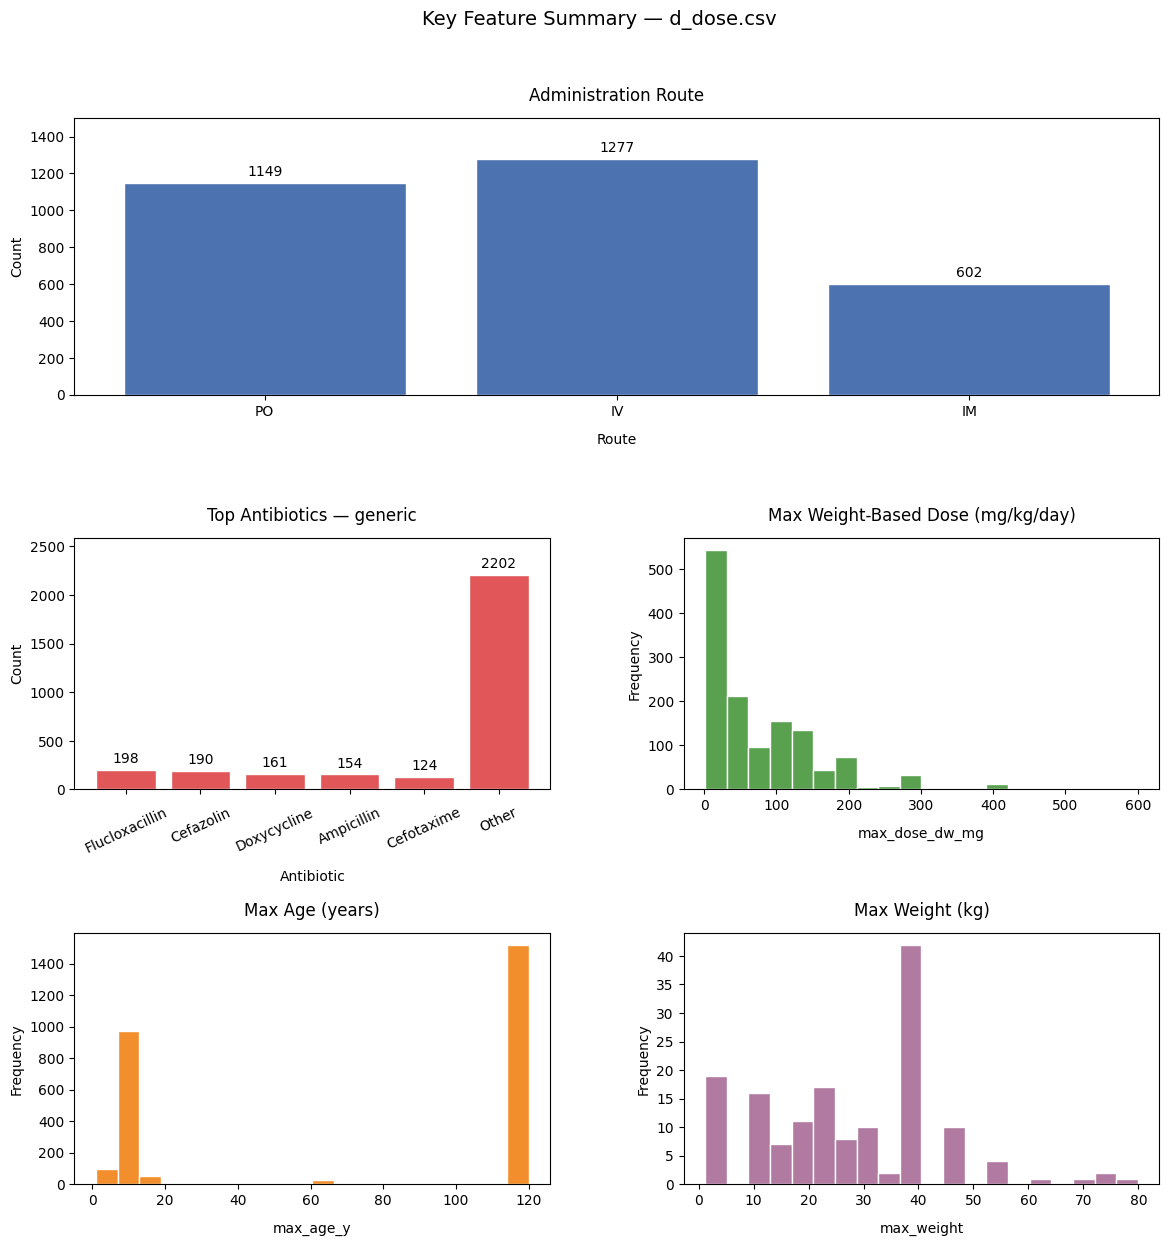

In [60]:
# Cell 11 · d_dose summary plots
plot_dosage_summary(df_raw_d_dose, "d_dose", "Key Feature Summary — d_dose.csv")


**Cell 12 · s_dose overview**

Standardized dosing regimens. Raw preview first, then one-hot encoding of low-cardinality fields (where applicable), unified summary, and summary plots.


In [61]:
# Cell 13 · s_dose load & preview
df_raw_s_dose = clean_dataset(load_dataset(DATASETS["s_dose"]))
df_raw_s_dose.head()


s_dose.csv: 288 rows × 20 columns


,generic,min_age_d,max_age_d,min_age_m,max_age_m,min_age_y,max_age_y,min_weight,max_weight,min_dose_dw_mg,max_dose_dw_mg,min_dose_dw_iu,max_dose_dw_iu,limit_mg,limit_iu,min_dose_dd_mg,max_dose_dd_mg,min_dose_dd_UNIT,max_dose_dd_iu,route
0,Amikacin,NaN,NaN,NaN,NaN,12.0,65.0,NaN,NaN,10.0,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IM
1,Amikacin,NaN,NaN,NaN,NaN,12.0,65.0,NaN,NaN,10.0,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IV
2,Amikacin,NaN,NaN,1.0,NaN,NaN,11.0,NaN,NaN,10.0,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IM
3,Amikacin,1.0,29.0,NaN,NaN,NaN,NaN,NaN,NaN,10.0,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IM
4,Amikacin,NaN,NaN,1.0,NaN,NaN,11.0,NaN,NaN,10.0,15.0,NaN,NaN,1500.0,NaN,NaN,NaN,NaN,NaN,IV


In [62]:
# Cell 14 · s_dose encode & column overview
df_s_dose = encode_dataset(df_raw_s_dose, "s_dose")
measurement_levels_s_dose = build_measurement_levels(df_s_dose)
column_overview_s_dose = build_column_overview(df_raw_s_dose, "s_dose")
column_overview_s_dose


Analysis shape: 288 rows × 22 columns


,unique_values,measurement_level
column,,
generic,89,nominal
route,3,nominal


In [63]:
# Cell 15 · s_dose unified summary
unified_summary_s_dose = build_unified_summary(df_s_dose, measurement_levels_s_dose)
unified_summary_s_dose


C:\Users\tnewman\AppData\Local\Temp\ipykernel_38796\3545277948.py:110: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  "skew": stats.skew(numeric.dropna(), bias=False)
C:\Users\tnewman\AppData\Local\Temp\ipykernel_38796\3545277948.py:110: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  "skew": stats.skew(numeric.dropna(), bias=False)
C:\Users\tnewman\AppData\Local\Temp\ipykernel_38796\3545277948.py:110: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  "skew": stats.skew(numeric.dropna(), bias=False)


,data_type,measurement_level,count,missing,unique_values,mean,median,mode,min,max,range,skew,iqr_outlier_count
column,,,,,,,,,,,,,
generic,str,nominal,288,0,89,NaN,NaN,Gentamicin,NaN,NaN,NaN,NaN,<NA>
min_age_d,float64,ratio,44,244,3,5.136,1.0,1.0,1.00,29.0,28.00,2.107,0
max_age_d,float64,ratio,36,252,2,27.778,29.0,29.0,7.00,29.0,22.00,-4.051,0
min_age_m,float64,ratio,95,193,5,1.916,1.0,1.0,1.00,9.0,8.00,2.478,9
max_age_m,float64,ratio,2,286,2,6.000,6.0,3.0,3.00,9.0,6.00,NaN,0
min_age_y,float64,ratio,149,139,7,11.711,12.0,12.0,1.00,18.0,17.00,-1.473,0
max_age_y,float64,ratio,250,38,6,69.304,120.0,120.0,1.00,120.0,119.00,-0.148,0
min_weight,float64,ratio,16,272,10,45.114,47.1,0.0,0.00,79.6,79.60,-0.494,0
max_weight,float64,ratio,14,274,9,51.484,49.5,39.99,13.55,79.5,65.95,-0.215,0


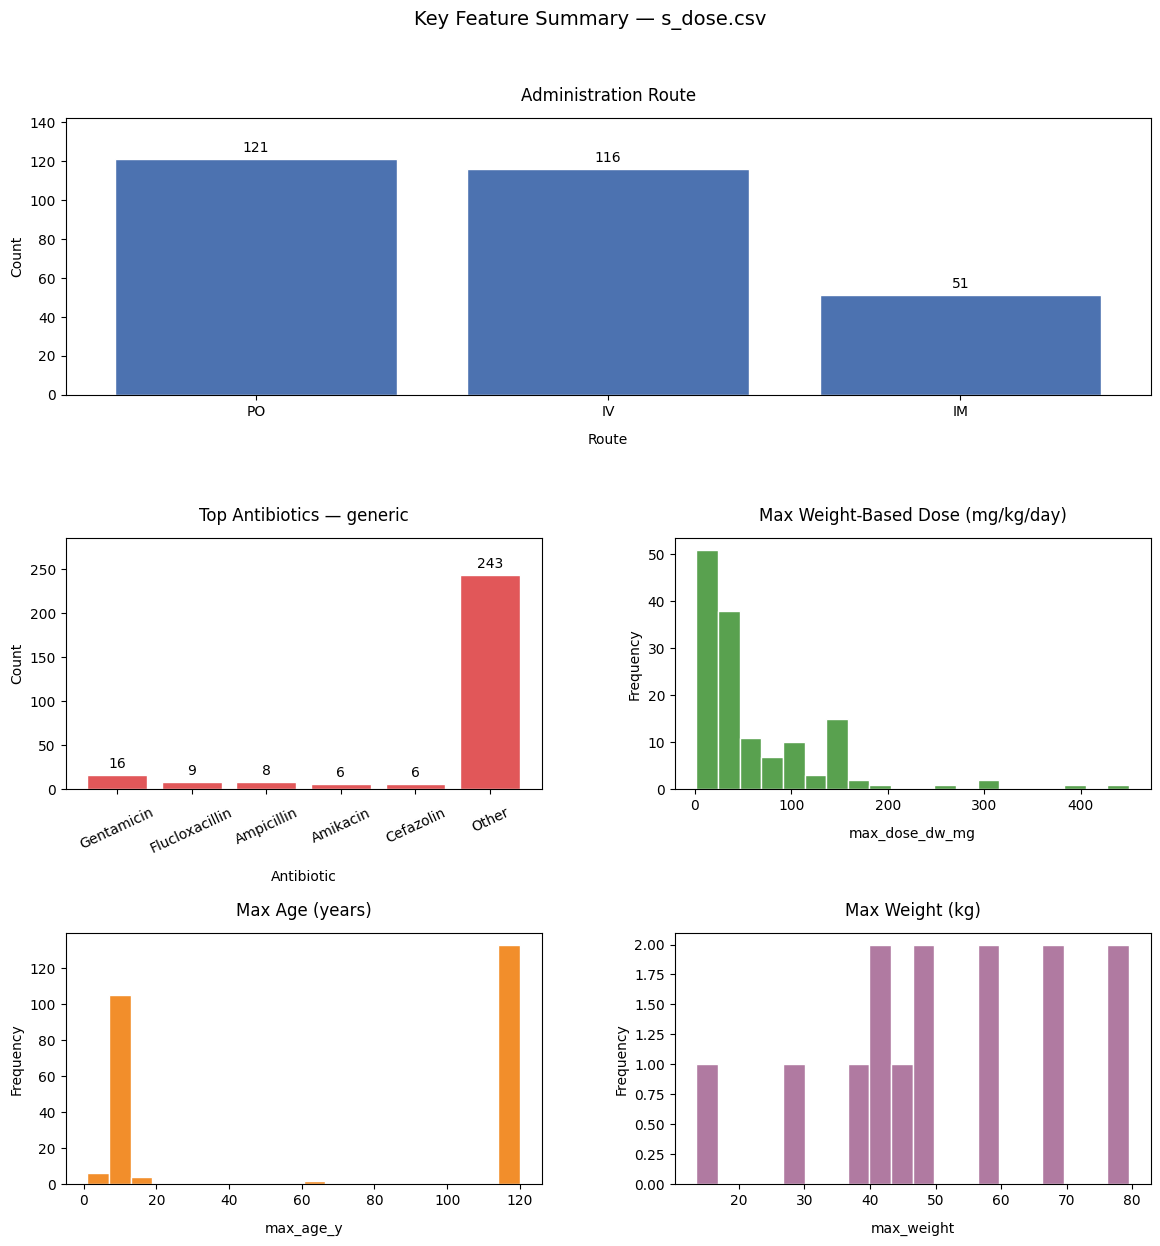

In [64]:
# Cell 16 · s_dose summary plots
plot_dosage_summary(df_raw_s_dose, "s_dose", "Key Feature Summary — s_dose.csv")


**Cell 17 · r_dose overview**

Renal dose adjustments. Raw preview first, then one-hot encoding of low-cardinality fields (where applicable), unified summary, and summary plots.


In [65]:
# Cell 18 · r_dose load & preview
df_raw_r_dose = clean_dataset(load_dataset(DATASETS["r_dose"]))
df_raw_r_dose.head()


r_dose.csv: 220 rows × 12 columns


,generic,disease,min_weight,max_weight,min_crcl,max_crcl,max_dose_dd_mg,max_dose_dw_mg,max_dose_dd_iu,route,flag
0,Amikacin,NaN,NaN,NaN,70.0,89.0,NaN,12.00,NaN,IV,NaN
1,Amikacin,NaN,NaN,NaN,50.0,69.0,NaN,7.50,NaN,IV,NaN
2,Amikacin,NaN,NaN,NaN,30.0,49.0,NaN,4.00,NaN,IV,NaN
3,Amikacin,NaN,NaN,NaN,30.0,39.0,NaN,4.00,NaN,IV,NaN
4,Amikacin,NaN,NaN,NaN,20.0,29.0,NaN,3.75,NaN,IV,NaN


In [66]:
# Cell 19 · r_dose encode & column overview
df_r_dose = encode_dataset(df_raw_r_dose, "r_dose")
measurement_levels_r_dose = build_measurement_levels(df_r_dose)
column_overview_r_dose = build_column_overview(df_raw_r_dose, "r_dose")
column_overview_r_dose


Analysis shape: 220 rows × 14 columns


,unique_values,measurement_level
column,,
generic,73,nominal
disease,2,nominal
route,3,nominal


In [67]:
# Cell 20 · r_dose unified summary
unified_summary_r_dose = build_unified_summary(df_r_dose, measurement_levels_r_dose)
unified_summary_r_dose


,data_type,measurement_level,count,missing,unique_values,mean,median,mode,min,max,range,skew,iqr_outlier_count
column,,,,,,,,,,,,,
generic,str,nominal,220,0,73,NaN,NaN,Gentamicin,NaN,NaN,NaN,NaN,<NA>
disease,str,nominal,6,214,2,NaN,NaN,Pneumocystis carinii pneumonia,NaN,NaN,NaN,NaN,<NA>
min_weight,float64,ratio,30,190,6,49.900,54.6,0.0,0.0,81.00,81.00,-0.869,0
max_weight,float64,ratio,25,195,5,59.798,59.5,39.5,39.5,80.99,41.49,0.067,0
min_crcl,float64,ratio,198,22,21,16.480,10.0,0.0,0.0,70.00,70.00,1.112,0
max_crcl,float64,ratio,197,23,23,35.853,30.0,29.0,4.0,90.00,86.00,0.863,0
max_dose_dd_mg,float64,ratio,165,55,41,1752.412,500.0,1000.0,0.0,14400.00,14400.00,2.574,18
max_dose_dw_mg,float64,ratio,26,194,11,5.681,4.0,2.5,0.7,25.00,24.30,2.285,1
max_dose_dd_iu,float64,ratio,2,218,2,450000.000,450000.0,300000.0,300000.0,600000.00,300000.00,NaN,0


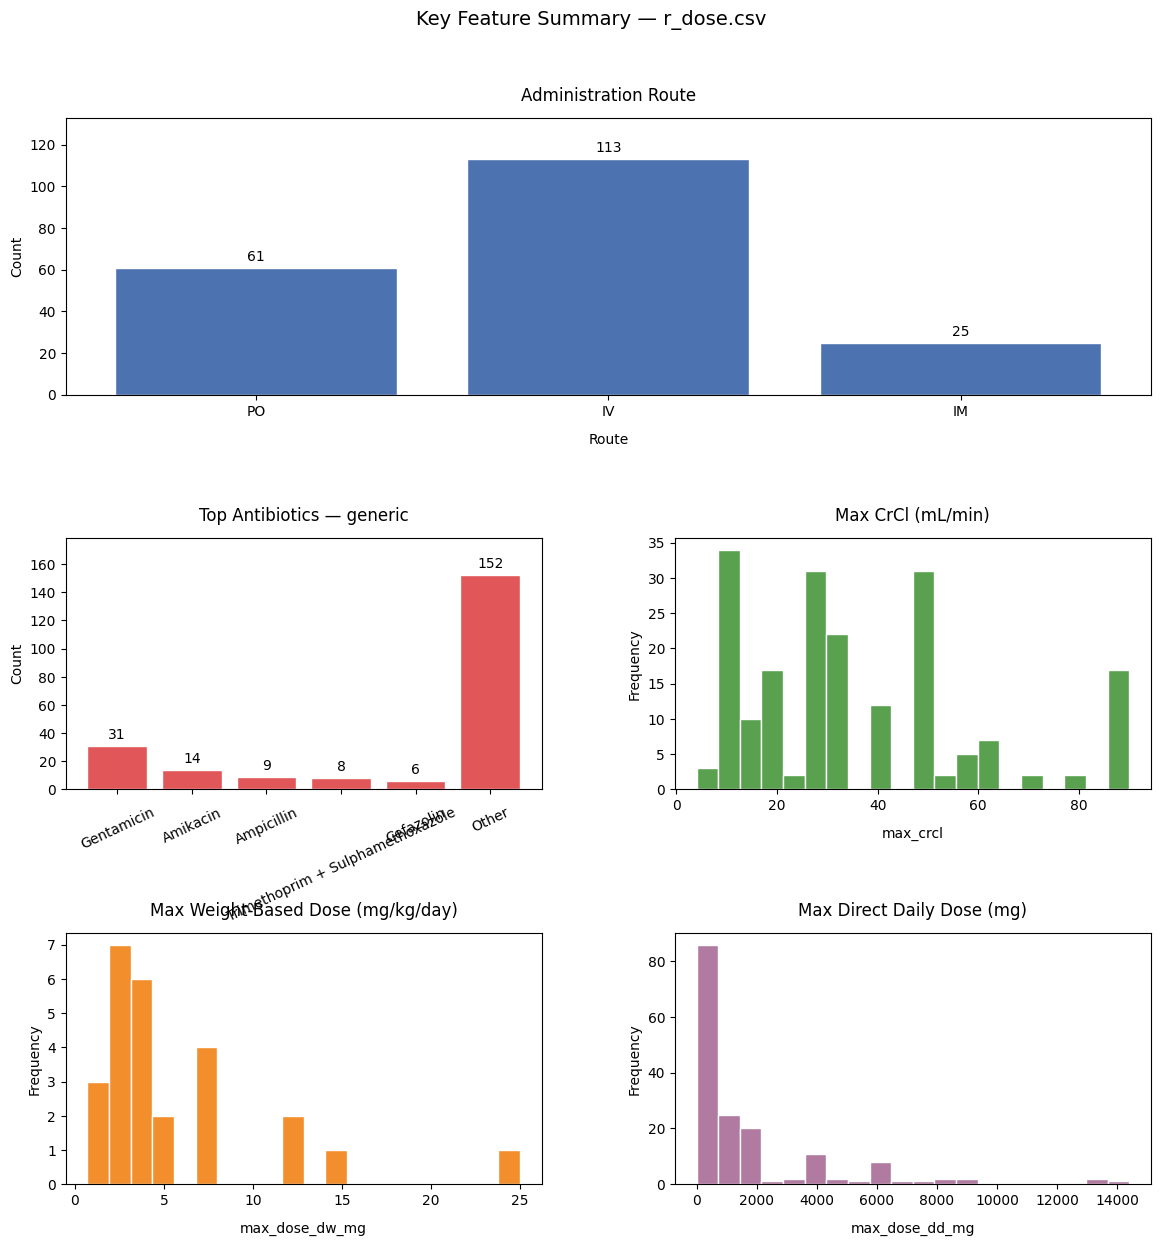

In [68]:
# Cell 21 · r_dose summary plots
plot_dosage_summary(df_raw_r_dose, "r_dose", "Key Feature Summary — r_dose.csv")


**Cell 22 · preg_risk overview**

FDA pregnancy risk classifications. Raw preview first, then one-hot encoding of low-cardinality fields (where applicable), unified summary, and summary plots.


In [69]:
# Cell 23 · preg_risk load & preview
df_raw_preg_risk = clean_dataset(load_dataset(DATASETS["preg_risk"]))
df_raw_preg_risk.head()


preg_risk.csv: 98 rows × 2 columns


,generic,r_category
0,Amikacin,D
1,Amikacin,D
2,Amoxicillin,B
3,Amoxicillin + Clavulanic Acid,B
4,Amphotericin B,B


In [70]:
# Cell 24 · preg_risk encode & column overview
df_preg_risk = encode_dataset(df_raw_preg_risk, "preg_risk")
measurement_levels_preg_risk = build_measurement_levels(df_preg_risk)
column_overview_preg_risk = build_column_overview(df_raw_preg_risk, "preg_risk")
column_overview_preg_risk


Analysis shape: 98 rows × 2 columns


,unique_values,measurement_level
column,,
generic,97,nominal
r_category,5,ordinal


In [71]:
# Cell 25 · preg_risk unified summary
unified_summary_preg_risk = build_unified_summary(df_preg_risk, measurement_levels_preg_risk)
unified_summary_preg_risk


,data_type,measurement_level,count,missing,unique_values,mean,median,mode,min,max,range,skew,iqr_outlier_count
column,,,,,,,,,,,,,
generic,str,nominal,98,0,97,NaN,NaN,Amikacin,NaN,NaN,NaN,NaN,<NA>
r_category_ordinal,float64,ordinal,91,7,3,1.582,1.0,1.0,1.0,3.0,2.0,0.818,0


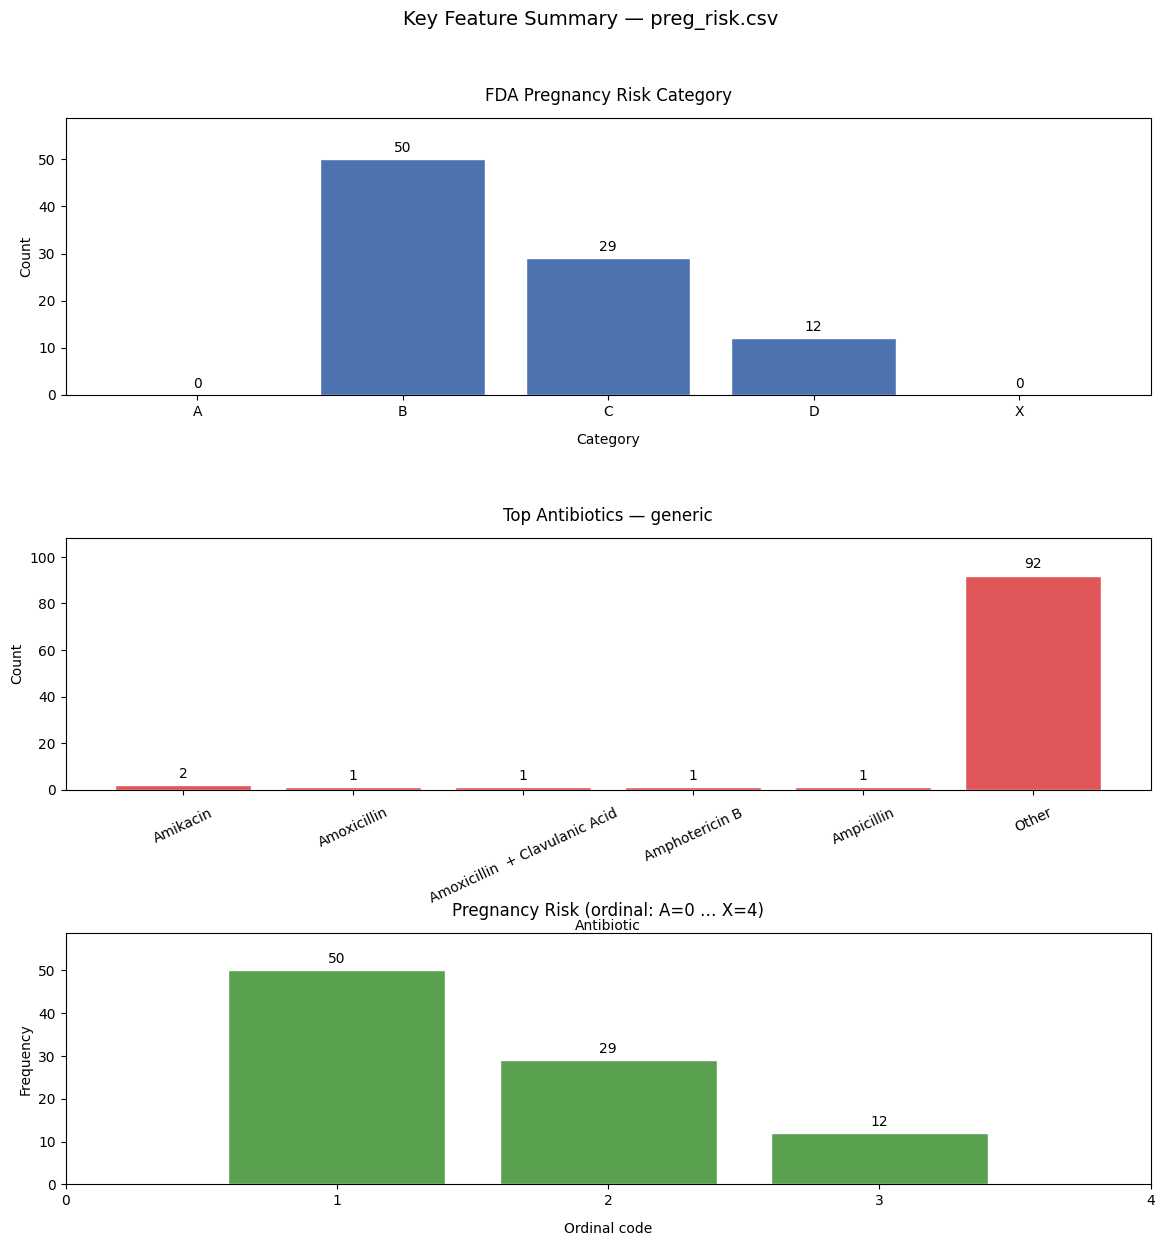

In [72]:
# Cell 26 · preg_risk summary plots
plot_dosage_summary(df_raw_preg_risk, "preg_risk", "Key Feature Summary — preg_risk.csv")


**Cell 27 · generic_disease_map overview**

Antibiotic–disease lookup. Raw preview first, then one-hot encoding of low-cardinality fields (where applicable), unified summary, and summary plots.


In [73]:
# Cell 28 · generic_disease_map load & preview
df_raw_generic_disease_map = clean_dataset(load_dataset(DATASETS["generic_disease_map"]))
df_raw_generic_disease_map.head()


generic_disease_map.csv: 1,066 rows × 2 columns


,generic,disease
0,Amikacin,Bacteremia
1,Amikacin,Bacterial Infection
2,Amikacin,Bone and Joint Infection
3,Amikacin,Intraabdominal Infection
4,Amikacin,Meningitis


In [74]:
# Cell 29 · generic_disease_map encode & column overview
df_generic_disease_map = encode_dataset(df_raw_generic_disease_map, "generic_disease_map")
measurement_levels_generic_disease_map = build_measurement_levels(df_generic_disease_map)
column_overview_generic_disease_map = build_column_overview(df_raw_generic_disease_map, "generic_disease_map")
column_overview_generic_disease_map


Analysis shape: 1,066 rows × 2 columns


,unique_values,measurement_level
column,,
generic,97,nominal
disease,267,nominal


In [75]:
# Cell 30 · generic_disease_map unified summary
unified_summary_generic_disease_map = build_unified_summary(df_generic_disease_map, measurement_levels_generic_disease_map)
unified_summary_generic_disease_map


,data_type,measurement_level,count,missing,unique_values,mean,median,mode,min,max,range,skew,iqr_outlier_count
column,,,,,,,,,,,,,
generic,str,nominal,1066,0,97,NaN,NaN,Doxycycline,NaN,NaN,NaN,NaN,<NA>
disease,str,nominal,1065,1,267,NaN,NaN,Pneumonia,NaN,NaN,NaN,NaN,<NA>


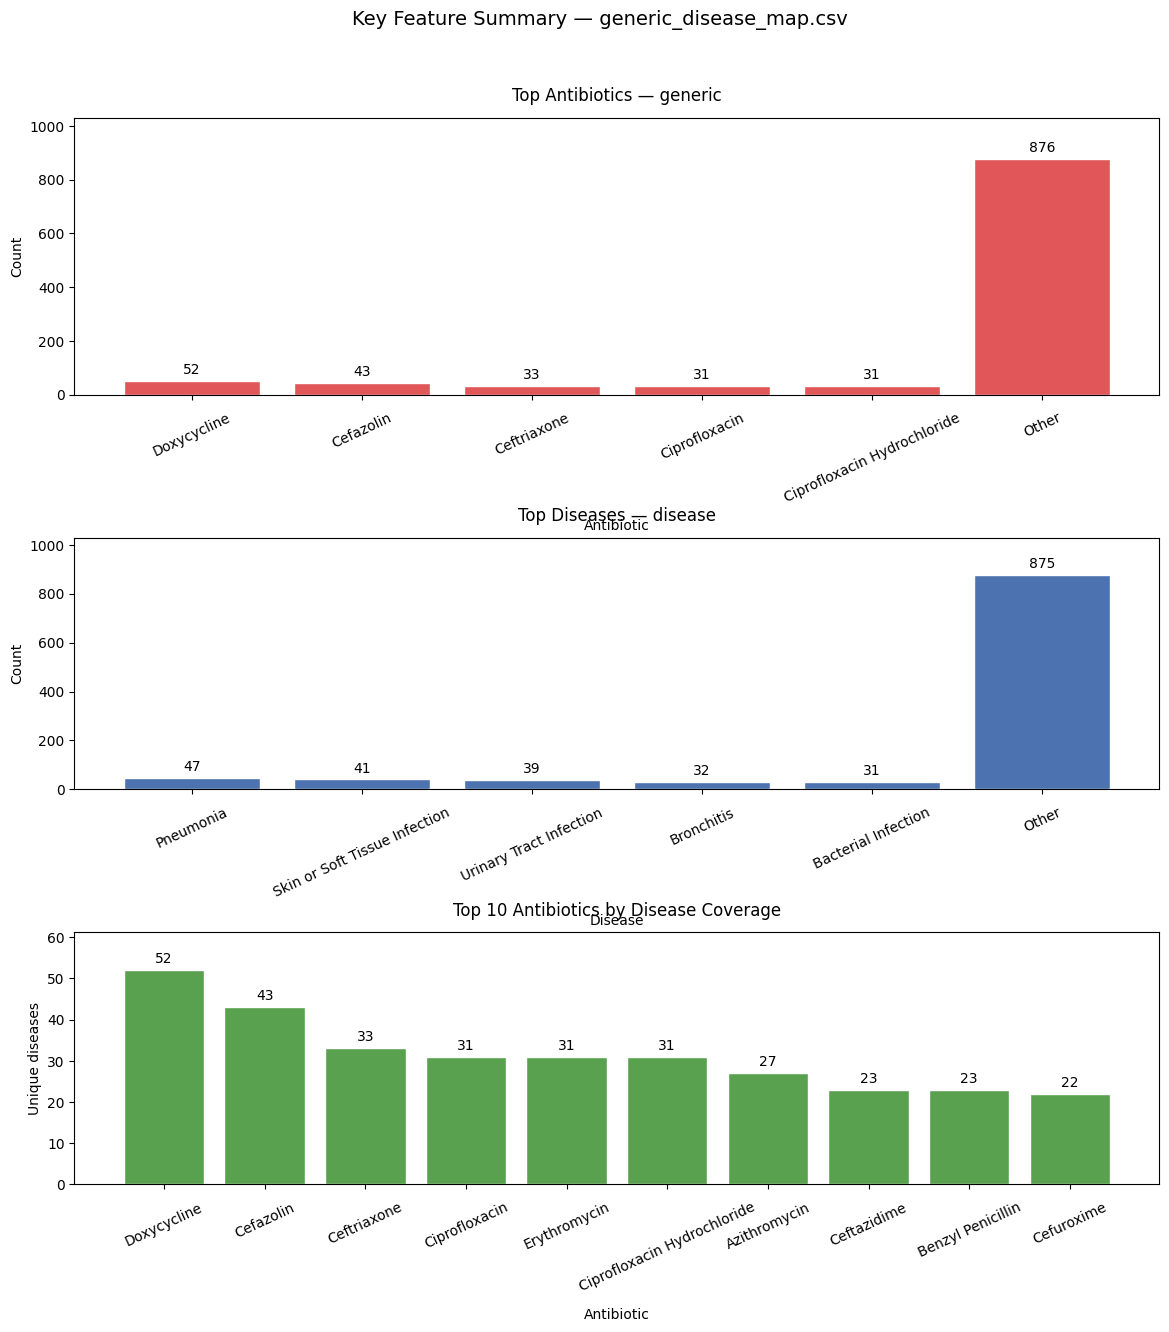

In [76]:
# Cell 31 · generic_disease_map summary plots
plot_dosage_summary(df_raw_generic_disease_map, "generic_disease_map", "Key Feature Summary — generic_disease_map.csv")


**Cell 32 · Lift by condition overview**

## Top rule sets by lift (d_dose conditions)

Each **`d_dose`** row is one authored dosing rule. A **condition** is the **`disease`** value; a **rule set** is the antecedent signature for that row ( **`generic`**, **`route`**, and populated age/weight/dose fields — everything except **`disease`**).

Across all rule rows, for condition **D** and rule set **S**:

$$\mathrm{lift}(S, D) = \frac{P(S \land D)}{P(S)\,P(D)}$$

Values above 1 mean the rule set co-occurs with the disease more often than independence would predict. The next cell shows **one table per condition** (10 most common diseases by rule count), each with the **10 highest-lift rule sets** in plain language. Results are also written under **`compiled/`**.


In [77]:
# Cell 33 · Lift by condition tables
# Top 10 rule sets by lift for each of the top 10 most common conditions (d_dose)
from pathlib import Path

from IPython.display import display

if "_tables" in globals() and "d_dose" in _tables:
    df_dose_rules = _tables["d_dose"].copy()
elif "clean_dataset" in globals() and "load_dataset" in globals():
    df_dose_rules = clean_dataset(load_dataset(DATASETS["d_dose"]))
else:
    _path = (
        DATASETS["d_dose"]
        if "DATASETS" in globals()
        else Path(".") / "d_dose.csv"
    )
    df_dose_rules = pd.read_csv(_path)

_data_dir = DATA_DIR if "DATA_DIR" in globals() else Path(".")
LIFT_EXPORT_DIR = _data_dir / "compiled" / "lift_by_condition"
LIFT_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
LIFT_EXPORT_ALL = _data_dir / "compiled" / "top_rule_sets_by_lift.csv"

RULE_SET_COLS = [
    "generic",
    "route",
    "min_age_d",
    "max_age_d",
    "min_age_m",
    "max_age_m",
    "min_age_y",
    "max_age_y",
    "min_weight",
    "max_weight",
    "min_dose_dw_mg",
    "max_dose_dw_mg",
    "min_dose_dw_iu",
    "max_dose_dw_iu",
    "limit_mg",
    "limit_iu",
    "min_dose_dd_mg",
    "max_dose_dd_mg",
    "min_dose_dd_UNIT",
    "max_dose_dd_iu",
]
TOP_N_CONDITIONS = 10
TOP_N_RULE_SETS = 10
MIN_ROWS_WITHIN_CONDITION = 2

DISPLAY_COLS = [
    "rank",
    "lift",
    "matching_rows",
    "dosing_rule",
]


def _fmt_num(val) -> str:
    if pd.isna(val):
        return ""
    f = float(val)
    return str(int(f)) if f == int(f) else str(f)


def _fmt_range(row: pd.Series, min_col: str, max_col: str, unit: str) -> str | None:
    lo, hi = row.get(min_col), row.get(max_col)
    if pd.isna(lo) and pd.isna(hi):
        return None
    if pd.notna(lo) and pd.notna(hi):
        return f"{_fmt_num(lo)}–{_fmt_num(hi)} {unit}"
    if pd.notna(lo):
        return f"≥ {_fmt_num(lo)} {unit}"
    return f"≤ {_fmt_num(hi)} {unit}"


def format_dosing_rule_readable(row: pd.Series) -> str:
    """Plain-language antecedent + dose line for one d_dose rule row."""
    parts: list[str] = []
    drug = row.get("generic")
    if pd.notna(drug) and str(drug).strip():
        parts.append(f"Antibiotic: {drug}")
    route = row.get("route")
    if pd.notna(route) and str(route).strip():
        parts.append(f"Route: {str(route).upper()}")
    for min_c, max_c, unit in (
        ("min_age_y", "max_age_y", "years"),
        ("min_age_m", "max_age_m", "months"),
        ("min_age_d", "max_age_d", "days"),
    ):
        age = _fmt_range(row, min_c, max_c, unit)
        if age:
            parts.append(f"Age: {age}")
            break
    weight = _fmt_range(row, "min_weight", "max_weight", "kg")
    if weight:
        parts.append(f"Weight: {weight}")
    dw_mg = _fmt_range(row, "min_dose_dw_mg", "max_dose_dw_mg", "mg/kg/day")
    if dw_mg:
        parts.append(f"Weight-based dose: {dw_mg}")
    dw_iu = _fmt_range(row, "min_dose_dw_iu", "max_dose_dw_iu", "IU/kg/day")
    if dw_iu:
        parts.append(f"Weight-based dose: {dw_iu}")
    dd_mg = _fmt_range(row, "min_dose_dd_mg", "max_dose_dd_mg", "mg/day")
    if dd_mg:
        parts.append(f"Fixed daily dose: {dd_mg}")
    if pd.notna(row.get("limit_mg")):
        parts.append(f"Max daily dose: {_fmt_num(row['limit_mg'])} mg")
    if pd.notna(row.get("limit_iu")):
        parts.append(f"Max daily dose: {_fmt_num(row['limit_iu'])} IU")
    if pd.notna(row.get("max_dose_dd_iu")):
        parts.append(f"Max dose: {_fmt_num(row['max_dose_dd_iu'])} IU")
    return " · ".join(parts) if parts else "(no antecedent fields populated)"


def _rule_set_key(row: pd.Series) -> str:
    tokens: list[str] = []
    for col in RULE_SET_COLS:
        if col not in row.index:
            continue
        val = row[col]
        if pd.isna(val) or str(val).strip() == "":
            continue
        tokens.append(f"{col}={val}")
    return " | ".join(tokens) if tokens else "(empty)"


def _safe_filename(name: str) -> str:
    keep = []
    for ch in str(name):
        keep.append(ch if ch.isalnum() or ch in "-_ " else "_")
    return "".join(keep).strip().replace(" ", "_")[:80]


df_lift = df_dose_rules.dropna(subset=["disease"]).copy()
df_lift["rule_set_key"] = df_lift.apply(_rule_set_key, axis=1)
n_rules = len(df_lift)

top_conditions = (
    df_lift["disease"].value_counts().head(TOP_N_CONDITIONS).index.tolist()
)

lift_rows: list[dict] = []
lift_tables_by_condition: dict[str, pd.DataFrame] = {}

for condition in top_conditions:
    mask_d = df_lift["disease"] == condition
    count_d = int(mask_d.sum())
    support_d = count_d / n_rules

    candidates: list[dict] = []
    for rule_set_key, grp in df_lift.loc[mask_d].groupby("rule_set_key", sort=False):
        count_sd = int(len(grp))
        count_s = int((df_lift["rule_set_key"] == rule_set_key).sum())
        support_s = count_s / n_rules
        support_sd = count_sd / n_rules
        denom = support_s * support_d
        lift = float(support_sd / denom) if denom > 0 else float("nan")
        candidates.append(
            {
                "condition": condition,
                "condition_rule_rows": count_d,
                "rule_set_key": rule_set_key,
                "dosing_rule": format_dosing_rule_readable(grp.iloc[0]),
                "matching_rows": count_sd,
                "support_rule_set": round(support_s, 5),
                "support_condition": round(support_d, 5),
                "lift": round(lift, 4) if pd.notna(lift) else lift,
            }
        )

    cand_df = pd.DataFrame(candidates)
    if cand_df.empty:
        continue

    preferred = cand_df[cand_df["matching_rows"] >= MIN_ROWS_WITHIN_CONDITION]
    pool = preferred if len(preferred) >= TOP_N_RULE_SETS else cand_df
    pool = pool.sort_values(
        ["lift", "matching_rows"], ascending=[False, False], na_position="last"
    ).head(TOP_N_RULE_SETS)
    pool = pool.copy()
    pool["rank"] = range(1, len(pool) + 1)
    lift_rows.extend(pool.to_dict("records"))

    table = pool[
        ["rank", "lift", "matching_rows", "dosing_rule", "support_rule_set", "support_condition"]
    ].copy()
    lift_tables_by_condition[condition] = table

top_rule_sets_by_lift = pd.DataFrame(lift_rows)

export_cols = [
    "condition",
    "condition_rule_rows",
    "rank",
    "lift",
    "matching_rows",
    "dosing_rule",
    "support_rule_set",
    "support_condition",
    "rule_set_key",
]
top_rule_sets_by_lift[export_cols].to_csv(LIFT_EXPORT_ALL, index=False)

for condition, table in lift_tables_by_condition.items():
    out_path = LIFT_EXPORT_DIR / f"{_safe_filename(condition)}_top10_lift.csv"
    table.to_csv(out_path, index=False)

print(
    f"d_dose rule rows: {n_rules:,} | top {TOP_N_CONDITIONS} conditions | "
    f"top {TOP_N_RULE_SETS} rule sets by lift per condition\n"
    f"Exported: {LIFT_EXPORT_ALL}\n"
    f"Per-condition CSVs: {LIFT_EXPORT_DIR}"
)

for condition in top_conditions:
    if condition not in lift_tables_by_condition:
        continue
    n_cond = int(
        top_rule_sets_by_lift.loc[
            top_rule_sets_by_lift["condition"] == condition, "condition_rule_rows"
        ].iloc[0]
    )
    print(f"\n—— {condition} ({n_cond:,} rules in d_dose) ——")
    display(lift_tables_by_condition[condition][DISPLAY_COLS])


d_dose rule rows: 3,028 | top 10 conditions | top 10 rule sets by lift per condition
Exported: compiled\top_rule_sets_by_lift.csv
Per-condition CSVs: compiled\lift_by_condition

—— Pneumonia (150 rules in d_dose) ——


,rank,lift,matching_rows,dosing_rule
6,1,20.1867,1,Antibiotic: Amoxicillin · Route: PO · Age: 18–...
36,2,20.1867,1,Antibiotic: Cefazolin · Route: IM · Age: 12–12...
37,3,20.1867,1,Antibiotic: Cefazolin · Route: IV · Age: 12–12...
88,4,20.1867,1,Antibiotic: Dicloxacillin · Route: PO · Age: 1...
8,5,10.0933,1,Antibiotic: Amoxicillin · Route: PO · Age: ≤ 1...
9,6,10.0933,1,Antibiotic: Amoxicillin + Clavulanic Acid · R...
33,7,10.0933,1,Antibiotic: Benzyl Penicillin+ Procaine Penic...
45,8,10.0933,1,Antibiotic: Cefditoren · Route: PO · Age: 12–1...
60,9,10.0933,1,Antibiotic: Cefpodoxime · Route: PO · Age: 12–...
61,10,10.0933,1,Antibiotic: Cefpodoxime + Clavulanic Acid · R...



—— Urinary Tract Infection (143 rules in d_dose) ——


,rank,lift,matching_rows,dosing_rule
20,1,21.1748,1,Antibiotic: Aztreonam · Route: IV · Age: 18–12...
31,2,21.1748,1,Antibiotic: Cefazolin · Route: IM · Age: 12–12...
32,3,21.1748,1,Antibiotic: Cefazolin · Route: IV · Age: 12–12...
81,4,21.1748,1,Antibiotic: Ciprofloxacin · Route: IV · Age: 1...
89,5,21.1748,1,Antibiotic: Ciprofloxacin Hydrochloride · Rout...
109,6,21.1748,1,Antibiotic: Fosfomycin · Route: IV · Age: 12–1...
122,7,21.1748,1,Antibiotic: Levofloxacin · Route: IV · Age: 12...
123,8,21.1748,1,Antibiotic: Levofloxacin · Route: PO · Age: 12...
125,9,21.1748,1,Antibiotic: Nalidixic Acid · Route: PO · Age: ...
126,10,21.1748,1,Antibiotic: Nalidixic Acid · Route: PO · Age: ...



—— Bacterial Infection (131 rules in d_dose) ——


,rank,lift,matching_rows,dosing_rule
2,1,23.1145,1,Antibiotic: Amikacin · Route: IM · Age: 1–7 da...
3,2,23.1145,1,Antibiotic: Amikacin · Route: IM · Age: 8–29 d...
4,3,23.1145,1,Antibiotic: Amikacin · Route: IM · Age: 1–7 da...
5,4,23.1145,1,Antibiotic: Amikacin · Route: IM · Age: 8–29 d...
7,5,23.1145,1,Antibiotic: Amikacin · Route: IV · Age: 1–7 da...
8,6,23.1145,1,Antibiotic: Amikacin · Route: IV · Age: 8–29 d...
9,7,23.1145,1,Antibiotic: Amikacin · Route: IV · Age: 1–7 da...
10,8,23.1145,1,Antibiotic: Amikacin · Route: IV · Age: 8–29 d...
15,9,23.1145,1,Antibiotic: Ampicillin · Route: IM · Age: ≤ 11...
18,10,23.1145,1,Antibiotic: Ampicillin · Route: IV · Age: ≤ 11...


... (10 outputs left out)


—— Bronchitis (72 rules in d_dose) ——


,rank,lift,matching_rows,dosing_rule
4,1,42.0556,1,Antibiotic: Ampicillin · Route: IM · Age: 12–1...
5,2,42.0556,1,Antibiotic: Ampicillin · Route: IV · Age: 12–1...
6,3,42.0556,1,Antibiotic: Ampicillin · Route: PO · Age: 12–1...
17,4,42.0556,1,Antibiotic: Cefdinir · Route: PO · Age: 18–120...
42,5,42.0556,1,Antibiotic: Dicloxacillin · Route: PO · Age: 1...
0,6,21.0278,1,Antibiotic: Amoxicillin · Route: PO · Age: 12–...
2,7,21.0278,1,Antibiotic: Amoxicillin · Route: PO · Age: ≤ 1...
3,8,21.0278,1,Antibiotic: Amoxicillin + Clavulanic Acid · R...
14,9,21.0278,1,Antibiotic: Azithromycin · Route: PO · Age: 18...
15,10,21.0278,1,Antibiotic: Cefaclor · Route: PO · Age: 18–120...



—— Bacteremia (63 rules in d_dose) ——


,rank,lift,matching_rows,dosing_rule
11,1,48.0635,1,Antibiotic: Cefoperazone · Route: IM · Age: 18...
12,2,48.0635,1,Antibiotic: Cefoperazone · Route: IV · Age: 18...
38,3,48.0635,1,Antibiotic: Gentamicin · Route: IM · Age: 12–1...
39,4,48.0635,1,Antibiotic: Gentamicin · Route: IV · Age: 12–1...
57,5,48.0635,1,Antibiotic: Vancomycin · Route: IV · Age: 1–29...
60,6,48.0635,1,Antibiotic: Vancomycin · Route: PO · Age: 1–29...
6,7,24.0317,1,Antibiotic: Aztreonam · Route: IV · Age: 18–12...
9,8,16.0212,1,Antibiotic: Cefepime · Route: IV · Age: 1–29 d...
7,9,12.0159,1,Antibiotic: Cefepime · Route: IV · Age: 12–120...
36,10,12.0159,1,Antibiotic: Erythromycin · Route: PO · Age: 12...


**Cell 34 · Confidence by condition overview**

Same layout as Cell 33, but each condition table lists the **10 rule sets with highest confidence** for that disease.

For rule set **S** and condition **D** (disease), **confidence** = P(S | D) = (matching rule rows for S and D) / (all `d_dose` rows for D).

Run Cell 33 first (shared rule-set keys and `top_conditions`), or this cell rebuilds from `d_dose` if needed.


In [78]:
# Cell 35 · Confidence by condition tables
from pathlib import Path

from IPython.display import display

if "df_lift" in globals() and "n_rules" in globals() and "top_conditions" in globals():
    df_conf = df_lift
    n_rules_conf = n_rules
    conditions = top_conditions
else:
    if "_tables" in globals() and "d_dose" in _tables:
        df_dose_rules = _tables["d_dose"].copy()
    elif "clean_dataset" in globals() and "load_dataset" in globals():
        df_dose_rules = clean_dataset(load_dataset(DATASETS["d_dose"]))
    else:
        _path = (
            DATASETS["d_dose"]
            if "DATASETS" in globals()
            else Path(".") / "d_dose.csv"
        )
        df_dose_rules = pd.read_csv(_path)

    if "RULE_SET_COLS" not in globals():
        RULE_SET_COLS = [
            "generic", "route", "min_age_d", "max_age_d", "min_age_m", "max_age_m",
            "min_age_y", "max_age_y", "min_weight", "max_weight",
            "min_dose_dw_mg", "max_dose_dw_mg", "min_dose_dw_iu", "max_dose_dw_iu",
            "limit_mg", "limit_iu", "min_dose_dd_mg", "max_dose_dd_mg",
            "min_dose_dd_UNIT", "max_dose_dd_iu",
        ]
    if "_rule_set_key" not in globals():

        def _rule_set_key(row: pd.Series) -> str:
            tokens: list[str] = []
            for col in RULE_SET_COLS:
                if col not in row.index:
                    continue
                val = row[col]
                if pd.isna(val) or str(val).strip() == "":
                    continue
                tokens.append(f"{col}={val}")
            return " | ".join(tokens) if tokens else "(empty)"

    if "format_dosing_rule_readable" not in globals():
        raise NameError("Run Cell 33 first, or ensure format_dosing_rule_readable is defined.")

    df_conf = df_dose_rules.dropna(subset=["disease"]).copy()
    df_conf["rule_set_key"] = df_conf.apply(_rule_set_key, axis=1)
    n_rules_conf = len(df_conf)
    TOP_N_CONDITIONS = 10
    conditions = (
        df_conf["disease"].value_counts().head(TOP_N_CONDITIONS).index.tolist()
    )

if "TOP_N_RULE_SETS" not in globals():
    TOP_N_RULE_SETS = 10
if "MIN_ROWS_WITHIN_CONDITION" not in globals():
    MIN_ROWS_WITHIN_CONDITION = 2
if "_safe_filename" not in globals():

    def _safe_filename(name: str) -> str:
        keep = []
        for ch in str(name):
            keep.append(ch if ch.isalnum() or ch in "-_ " else "_")
        return "".join(keep).strip().replace(" ", "_")[:80]

_data_dir = DATA_DIR if "DATA_DIR" in globals() else Path(".")
CONFIDENCE_EXPORT_DIR = _data_dir / "compiled" / "confidence_by_condition"
CONFIDENCE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
CONFIDENCE_EXPORT_ALL = _data_dir / "compiled" / "top_rule_sets_by_confidence.csv"

CONFIDENCE_DISPLAY_COLS = ["rank", "confidence", "matching_rows", "dosing_rule"]

confidence_rows: list[dict] = []
confidence_tables_by_condition: dict[str, pd.DataFrame] = {}

for condition in conditions:
    mask_d = df_conf["disease"] == condition
    count_d = int(mask_d.sum())
    support_d = count_d / n_rules_conf

    candidates: list[dict] = []
    for rule_set_key, grp in df_conf.loc[mask_d].groupby("rule_set_key", sort=False):
        count_sd = int(len(grp))
        confidence = count_sd / count_d if count_d else float("nan")
        candidates.append(
            {
                "condition": condition,
                "condition_rule_rows": count_d,
                "rule_set_key": rule_set_key,
                "dosing_rule": format_dosing_rule_readable(grp.iloc[0]),
                "matching_rows": count_sd,
                "confidence": round(confidence, 5),
                "support_condition": round(support_d, 5),
            }
        )

    cand_df = pd.DataFrame(candidates)
    if cand_df.empty:
        continue

    preferred = cand_df[cand_df["matching_rows"] >= MIN_ROWS_WITHIN_CONDITION]
    pool = preferred if len(preferred) >= TOP_N_RULE_SETS else cand_df
    pool = pool.sort_values(
        ["confidence", "matching_rows"], ascending=[False, False], na_position="last"
    ).head(TOP_N_RULE_SETS)
    pool = pool.copy()
    pool["rank"] = range(1, len(pool) + 1)
    confidence_rows.extend(pool.to_dict("records"))

    table = pool[
        [
            "rank",
            "confidence",
            "matching_rows",
            "dosing_rule",
            "support_condition",
        ]
    ].copy()
    confidence_tables_by_condition[condition] = table

top_rule_sets_by_confidence = pd.DataFrame(confidence_rows)

export_cols = [
    "condition",
    "condition_rule_rows",
    "rank",
    "confidence",
    "matching_rows",
    "dosing_rule",
    "support_condition",
    "rule_set_key",
]
top_rule_sets_by_confidence[export_cols].to_csv(CONFIDENCE_EXPORT_ALL, index=False)

for condition, table in confidence_tables_by_condition.items():
    out_path = CONFIDENCE_EXPORT_DIR / f"{_safe_filename(condition)}_top10_confidence.csv"
    table.to_csv(out_path, index=False)

print(
    f"d_dose rule rows: {n_rules_conf:,} | top {len(conditions)} conditions | "
    f"top {TOP_N_RULE_SETS} rule sets by confidence per condition\n"
    f"Exported: {CONFIDENCE_EXPORT_ALL}\n"
    f"Per-condition CSVs: {CONFIDENCE_EXPORT_DIR}"
)

for condition in conditions:
    if condition not in confidence_tables_by_condition:
        continue
    n_cond = int(
        top_rule_sets_by_confidence.loc[
            top_rule_sets_by_confidence["condition"] == condition, "condition_rule_rows"
        ].iloc[0]
    )
    print(f"\n—— {condition} ({n_cond:,} rules in d_dose) ——")
    display(confidence_tables_by_condition[condition][CONFIDENCE_DISPLAY_COLS])


d_dose rule rows: 3,028 | top 10 conditions | top 10 rule sets by confidence per condition
Exported: compiled\top_rule_sets_by_confidence.csv
Per-condition CSVs: compiled\confidence_by_condition

—— Pneumonia (150 rules in d_dose) ——


,rank,confidence,matching_rows,dosing_rule
2,1,0.01333,2,Antibiotic: Amikacin · Route: IM · Age: 65–120...
3,2,0.01333,2,Antibiotic: Amikacin · Route: IV · Age: 65–120...
0,3,0.00667,1,Antibiotic: Amikacin · Route: IM · Age: 12–65 ...
1,4,0.00667,1,Antibiotic: Amikacin · Route: IV · Age: 12–65 ...
4,5,0.00667,1,Antibiotic: Amikacin · Route: IM · Age: ≤ 11 y...
5,6,0.00667,1,Antibiotic: Amikacin · Route: IV · Age: ≤ 11 y...
6,7,0.00667,1,Antibiotic: Amoxicillin · Route: PO · Age: 18–...
7,8,0.00667,1,Antibiotic: Amoxicillin · Route: PO · Age: 1–3...
8,9,0.00667,1,Antibiotic: Amoxicillin · Route: PO · Age: ≤ 1...
9,10,0.00667,1,Antibiotic: Amoxicillin + Clavulanic Acid · R...



—— Urinary Tract Infection (143 rules in d_dose) ——


,rank,confidence,matching_rows,dosing_rule
0,1,0.00699,1,Antibiotic: Amikacin · Route: IM · Age: 12–65 ...
1,2,0.00699,1,Antibiotic: Amikacin · Route: IV · Age: 12–65 ...
2,3,0.00699,1,Antibiotic: Amikacin · Route: IM · Age: ≤ 11 y...
3,4,0.00699,1,Antibiotic: Amikacin · Route: IV · Age: ≤ 11 y...
4,5,0.00699,1,Antibiotic: Amoxicillin · Route: PO · Age: 12–...
5,6,0.00699,1,Antibiotic: Amoxicillin · Route: PO · Age: 1–3...
6,7,0.00699,1,Antibiotic: Amoxicillin · Route: PO · Age: ≤ 1...
7,8,0.00699,1,Antibiotic: Amoxicillin + Clavulanic Acid · R...
8,9,0.00699,1,Antibiotic: Amoxicillin + Clavulanic Acid · R...
9,10,0.00699,1,Antibiotic: Amoxicillin + Clavulanic Acid · R...



—— Bacterial Infection (131 rules in d_dose) ——


,rank,confidence,matching_rows,dosing_rule
0,1,0.00763,1,Antibiotic: Amikacin · Route: IM · Age: 12–65 ...
1,2,0.00763,1,Antibiotic: Amikacin · Route: IV · Age: 12–65 ...
2,3,0.00763,1,Antibiotic: Amikacin · Route: IM · Age: 1–7 da...
3,4,0.00763,1,Antibiotic: Amikacin · Route: IM · Age: 8–29 d...
4,5,0.00763,1,Antibiotic: Amikacin · Route: IM · Age: 1–7 da...
5,6,0.00763,1,Antibiotic: Amikacin · Route: IM · Age: 8–29 d...
6,7,0.00763,1,Antibiotic: Amikacin · Route: IM · Age: ≤ 11 y...
7,8,0.00763,1,Antibiotic: Amikacin · Route: IV · Age: 1–7 da...
8,9,0.00763,1,Antibiotic: Amikacin · Route: IV · Age: 8–29 d...
9,10,0.00763,1,Antibiotic: Amikacin · Route: IV · Age: 1–7 da...


... (10 outputs left out)


—— Bronchitis (72 rules in d_dose) ——


,rank,confidence,matching_rows,dosing_rule
0,1,0.01389,1,Antibiotic: Amoxicillin · Route: PO · Age: 12–...
1,2,0.01389,1,Antibiotic: Amoxicillin · Route: PO · Age: 1–3...
2,3,0.01389,1,Antibiotic: Amoxicillin · Route: PO · Age: ≤ 1...
3,4,0.01389,1,Antibiotic: Amoxicillin + Clavulanic Acid · R...
4,5,0.01389,1,Antibiotic: Ampicillin · Route: IM · Age: 12–1...
5,6,0.01389,1,Antibiotic: Ampicillin · Route: IV · Age: 12–1...
6,7,0.01389,1,Antibiotic: Ampicillin · Route: PO · Age: 12–1...
7,8,0.01389,1,Antibiotic: Ampicillin · Route: PO · Age: 12–1...
8,9,0.01389,1,Antibiotic: Ampicillin · Route: IM · Age: ≤ 11...
9,10,0.01389,1,Antibiotic: Ampicillin · Route: IM · Age: ≤ 11...



—— Bacteremia (63 rules in d_dose) ——


,rank,confidence,matching_rows,dosing_rule
2,1,0.03175,2,Antibiotic: Amikacin · Route: IM · Age: 65–120...
3,2,0.03175,2,Antibiotic: Amikacin · Route: IV · Age: 65–120...
0,3,0.01587,1,Antibiotic: Amikacin · Route: IM · Age: 12–65 ...
1,4,0.01587,1,Antibiotic: Amikacin · Route: IV · Age: 12–65 ...
4,5,0.01587,1,Antibiotic: Amikacin · Route: IM · Age: ≤ 11 y...
5,6,0.01587,1,Antibiotic: Amikacin · Route: IV · Age: ≤ 11 y...
6,7,0.01587,1,Antibiotic: Aztreonam · Route: IV · Age: 18–12...
7,8,0.01587,1,Antibiotic: Cefepime · Route: IV · Age: 12–120...
8,9,0.01587,1,Antibiotic: Cefepime · Route: IV · Age: ≤ 11 y...
9,10,0.01587,1,Antibiotic: Cefepime · Route: IV · Age: 1–29 d...


**Cell 36 · Practitioner dosage query (overview)**

Simulates a clinician entering **patient facts** (antibiotic, route, age, weight when applicable) and a **condition** (`disease` in `d_dose`). Each draw is **5 random examples** from real rule rows.

For each case the next cell:

1. Builds a **synthetic patient** whose age/weight fall inside the rule’s bands (when bands exist).
2. Looks up matching `d_dose` rules (same condition + **antecedent** signature — generic, route, age/weight bands).
3. Returns the **consequent dosage** line from the sampled rule as the recommendation.
4. Reports **lift** and **confidence** for that recommendation, plus rule-base **counts**:

| Metric | Meaning |
|--------|---------|
| **Lift** | How much more often this dosage co-occurs with the condition than independence would predict (rule-base). |
| **Confidence (Patient + Condition)** | Share of antecedent+condition rules that use this dosage (full-match rows ÷ antecedent+condition rows). |
| **Rule Rows (Condition + Dosage)** | Rows anywhere in `d_dose` with this **disease and dosage signature** (any antecedent). |
| **Rule Rows (Condition + Antecedent)** | Rows with this **disease and patient/antecedent band**. |
| **Rule Rows (Full Match)** | Rows matching **disease, antecedent, and this dosage** (usually the sampled rule). |
| **Unique Dosages (Antecedent + Condition)** | Distinct dosage signatures among rows that share the same antecedent + condition. |

Run Cell **33** first (shared formatters) or run this section after a fresh **`df_dose_rules`** load.


In [79]:
# Cell 37 · Practitioner query — 5 random cases (support, confidence, lift)
import numpy as np
import pandas as pd
from IPython.display import display

N_DEMO_CASES = 5
DEMO_RANDOM_STATE = 42

METRIC_DISPLAY_ORDER = [
    "Lift",
    "Confidence (Patient + Condition)",
    "Unique Dosages (Antecedent + Condition)",
    "Rule Rows (Condition + Dosage)",
    "Rule Rows (Condition + Antecedent)",
    "Rule Rows (Full Match)",
]

SUMMARY_COLUMNS = [
    "Example",
    "Antibiotic",
    "Route",
    "Condition",
    "Recommended Dosage",
    "Lift",
    "Confidence (Patient + Condition)",
    "Unique Dosages (Antecedent + Condition)",
    "Rule Rows (Full Match)",
]

ANTECEDENT_COLS = [
    "generic",
    "route",
    "min_age_d",
    "max_age_d",
    "min_age_m",
    "max_age_m",
    "min_age_y",
    "max_age_y",
    "min_weight",
    "max_weight",
]

DOSAGE_CONSEQUENT_COLS = [
    "min_dose_dw_mg",
    "max_dose_dw_mg",
    "min_dose_dw_iu",
    "max_dose_dw_iu",
    "limit_mg",
    "limit_iu",
    "min_dose_dd_mg",
    "max_dose_dd_mg",
    "min_dose_dd_UNIT",
    "max_dose_dd_iu",
]

if "df_lift" in globals():
    df_rules = df_lift.copy()
    n_rules_demo = n_rules
elif "df_dose_rules" in globals():
    df_rules = df_dose_rules.dropna(subset=["disease"]).copy()
    n_rules_demo = len(df_rules)
else:
    raise NameError("Run Cell 33 (or load d_dose) so df_lift / df_dose_rules exists.")

if "_fmt_num" not in globals() or "_fmt_range" not in globals():
    raise NameError("Run Cell 33 for _fmt_num / _fmt_range helpers.")


def _field_key(row: pd.Series, cols: list[str]) -> str:
    tokens: list[str] = []
    for col in cols:
        if col not in row.index:
            continue
        val = row[col]
        if pd.isna(val) or str(val).strip() == "":
            continue
        tokens.append(f"{col}={val}")
    return " | ".join(tokens) if tokens else "(empty)"


def format_antecedent_readable(row: pd.Series) -> str:
    parts: list[str] = []
    drug = row.get("generic")
    if pd.notna(drug) and str(drug).strip():
        parts.append(f"Antibiotic: {drug}")
    route = row.get("route")
    if pd.notna(route) and str(route).strip():
        parts.append(f"Route: {str(route).upper()}")
    for min_c, max_c, unit in (
        ("min_age_y", "max_age_y", "years"),
        ("min_age_m", "max_age_m", "months"),
        ("min_age_d", "max_age_d", "days"),
    ):
        age = _fmt_range(row, min_c, max_c, unit)
        if age:
            parts.append(f"Age band: {age}")
            break
    weight = _fmt_range(row, "min_weight", "max_weight", "kg")
    if weight:
        parts.append(f"Weight band: {weight}")
    return " · ".join(parts) if parts else "(no antecedent bands)"


def format_consequent_dosage(row: pd.Series) -> str:
    parts: list[str] = []
    dw_mg = _fmt_range(row, "min_dose_dw_mg", "max_dose_dw_mg", "mg/kg/day")
    if dw_mg:
        parts.append(f"Weight-based dose: {dw_mg}")
    dw_iu = _fmt_range(row, "min_dose_dw_iu", "max_dose_dw_iu", "IU/kg/day")
    if dw_iu:
        parts.append(f"Weight-based dose: {dw_iu}")
    dd_mg = _fmt_range(row, "min_dose_dd_mg", "max_dose_dd_mg", "mg/day")
    if dd_mg:
        parts.append(f"Fixed daily dose: {dd_mg}")
    if pd.notna(row.get("limit_mg")):
        parts.append(f"Max daily dose: {_fmt_num(row['limit_mg'])} mg")
    if pd.notna(row.get("limit_iu")):
        parts.append(f"Max daily dose: {_fmt_num(row['limit_iu'])} IU")
    if pd.notna(row.get("max_dose_dd_iu")):
        parts.append(f"Max dose: {_fmt_num(row['max_dose_dd_iu'])} IU")
    if pd.notna(row.get("min_dose_dd_UNIT")) and str(row.get("min_dose_dd_UNIT")).strip():
        parts.append(f"Fixed daily dose (units): {row['min_dose_dd_UNIT']}")
    return " · ".join(parts) if parts else "(no dose fields on this rule row)"


def _pick_in_band(lo, hi, rng: np.random.Generator, as_int: bool = True):
    if pd.isna(lo) and pd.isna(hi):
        return None
    if pd.notna(lo) and pd.notna(hi):
        a, b = float(lo), float(hi)
        val = rng.uniform(a, b)
        return int(round(val)) if as_int else round(val, 1)
    if pd.notna(lo):
        val = float(lo) + rng.uniform(0, max(1.0, float(lo) * 0.05))
        return int(round(val)) if as_int else round(val, 1)
    val = float(hi) - rng.uniform(0, max(1.0, float(hi) * 0.05))
    return int(round(val)) if as_int else round(val, 1)


def synthesize_patient_from_rule(row: pd.Series, rng: np.random.Generator) -> dict:
    patient: dict = {
        "generic": row.get("generic"),
        "route": str(row.get("route")).upper() if pd.notna(row.get("route")) else None,
        "condition (disease)": row.get("disease"),
    }
    age_y = _pick_in_band(row.get("min_age_y"), row.get("max_age_y"), rng)
    age_m = _pick_in_band(row.get("min_age_m"), row.get("max_age_m"), rng)
    age_d = _pick_in_band(row.get("min_age_d"), row.get("max_age_d"), rng)
    if age_y is not None:
        patient["age_years"] = age_y
    elif age_m is not None:
        patient["age_months"] = age_m
    elif age_d is not None:
        patient["age_days"] = age_d
    w = _pick_in_band(row.get("min_weight"), row.get("max_weight"), rng, as_int=False)
    if w is not None:
        patient["weight_kg"] = w
    return patient


def unique_dosage_options_table(df: pd.DataFrame, match_mask: pd.Series) -> pd.DataFrame:
    sub = df.loc[match_mask]
    rows: list[dict] = []
    for _, grp in sub.groupby("dosage_key", sort=False):
        rows.append(
            {
                "Dosage Option": format_consequent_dosage(grp.iloc[0]),
                "Rule Rows": int(len(grp)),
            }
        )
    out = pd.DataFrame(rows)
    if not out.empty:
        out = out.sort_values(["Rule Rows", "Dosage Option"], ascending=[False, True]).reset_index(
            drop=True
        )
    return out


def consequent_metrics(
    df: pd.DataFrame,
    disease: str,
    dosage_key: str,
    antecedent_key: str,
    n_total: int,
    n_unique_dosages: int,
) -> dict:
    mask_d = df["disease"] == disease
    mask_c = df["dosage_key"] == dosage_key
    mask_a = df["antecedent_key"] == antecedent_key
    count_d = int(mask_d.sum())
    count_c = int(mask_c.sum())
    count_cd = int((mask_d & mask_c).sum())
    count_ad = int((mask_d & mask_a).sum())
    count_acd = int((mask_d & mask_a & mask_c).sum())

    support_d = count_d / n_total
    support_c = count_c / n_total
    support_joint = count_cd / n_total
    denom = support_c * support_d
    lift = float(support_joint / denom) if denom > 0 else float("nan")
    confidence_case = count_acd / count_ad if count_ad else float("nan")

    return {
        "Lift": round(lift, 4) if pd.notna(lift) else lift,
        "Confidence (Patient + Condition)": round(confidence_case, 5)
        if pd.notna(confidence_case)
        else confidence_case,
        "Unique Dosages (Antecedent + Condition)": int(n_unique_dosages),
        "Rule Rows (Condition + Dosage)": count_cd,
        "Rule Rows (Condition + Antecedent)": count_ad,
        "Rule Rows (Full Match)": count_acd,
    }


def _metrics_display_frame(metrics: dict) -> pd.DataFrame:
    ordered = {k: metrics[k] for k in METRIC_DISPLAY_ORDER if k in metrics}
    return pd.DataFrame({"Value": ordered})


df_rules["antecedent_key"] = df_rules.apply(lambda r: _field_key(r, ANTECEDENT_COLS), axis=1)
df_rules["dosage_key"] = df_rules.apply(lambda r: _field_key(r, DOSAGE_CONSEQUENT_COLS), axis=1)

has_dose = df_rules["dosage_key"].ne("(empty)")
pool = df_rules.loc[has_dose & df_rules["disease"].notna()].copy()
if pool.empty:
    raise ValueError("No d_dose rows with disease and consequent dose fields.")

rng = np.random.default_rng(DEMO_RANDOM_STATE)
sample_idx = rng.choice(pool.index.to_numpy(), size=min(N_DEMO_CASES, len(pool)), replace=False)

demo_rows: list[dict] = []

for i, idx in enumerate(sample_idx, start=1):
    row = pool.loc[idx]
    disease = str(row["disease"])
    antecedent_key = row["antecedent_key"]
    dosage_key = row["dosage_key"]
    patient = synthesize_patient_from_rule(row, rng)

    match_mask = (df_rules["disease"] == disease) & (df_rules["antecedent_key"] == antecedent_key)
    n_match = int(match_mask.sum())
    dosage_options = unique_dosage_options_table(df_rules, match_mask)
    n_unique = int(df_rules.loc[match_mask, "dosage_key"].nunique())

    metrics = consequent_metrics(
        df_rules, disease, dosage_key, antecedent_key, n_rules_demo, n_unique
    )
    consequent = format_consequent_dosage(row)
    antecedent_band = format_antecedent_readable(row)
    patient_parts = [
        f"Antibiotic: {patient.get('generic')}",
        f"Route: {patient.get('route')}" if patient.get("route") else None,
    ]
    if "age_years" in patient:
        patient_parts.append(f"Age: {patient['age_years']} years (within rule band)")
    elif "age_months" in patient:
        patient_parts.append(f"Age: {patient['age_months']} months (within rule band)")
    elif "age_days" in patient:
        patient_parts.append(f"Age: {patient['age_days']} days (within rule band)")
    if "weight_kg" in patient:
        patient_parts.append(f"Weight: {patient['weight_kg']} kg (within rule band)")
    patient_line = " · ".join(p for p in patient_parts if p)

    print(f"\n{'=' * 72}")
    print(f"Example {i} — practitioner query → dosage recommendation")
    print(f"{'=' * 72}")
    print(f"Patient input: {patient_line}")
    print(f"Condition: {disease}")
    print(f"Matched antecedent band (d_dose): {antecedent_band}")
    print(f"\nRecommended dosage: {consequent}")
    print(f"({n_match} rule row(s) share this condition + antecedent band.)")

    if not dosage_options.empty:
        print(f"\nUnique dosage options for this antecedent + condition ({n_unique}):")
        display(dosage_options)

    print("\nAssociation metrics for this recommendation:")
    display(_metrics_display_frame(metrics))

    demo_rows.append(
        {
            "Example": i,
            "Antibiotic": patient.get("generic"),
            "Route": patient.get("route"),
            "Condition": disease,
            "Patient Summary": patient_line,
            "Recommended Dosage": consequent,
            **metrics,
        }
    )

practitioner_demo_summary = pd.DataFrame(demo_rows)
print(f"\n{'=' * 72}")
print(f"Summary — {len(practitioner_demo_summary)} simulated practitioner queries (seed={DEMO_RANDOM_STATE})")
print(f"Rule base: {n_rules_demo:,} d_dose rows")
display(practitioner_demo_summary[SUMMARY_COLUMNS])



Example 1 — practitioner query → dosage recommendation
Patient input: Antibiotic: Imipenem + Cilastatin · Route: IV · Age: 3 months (within rule band)
Condition: Septicemia
Matched antecedent band (d_dose): Antibiotic: Imipenem + Cilastatin · Route: IV · Age band: 1–3 months

Recommended dosage: Weight-based dose: 100–125 mg/kg/day · Max daily dose: 4000 mg
(1 rule row(s) share this condition + antecedent band.)

Unique dosage options for this antecedent + condition (1):


,Dosage Option,Rule Rows
0,Weight-based dose: 100–125 mg/kg/day · Max dai...,1



Association metrics for this recommendation:


,Value
Lift,3.4409
Confidence (Patient + Condition),1.0000
Unique Dosages (Antecedent + Condition),1.0000
Rule Rows (Condition + Dosage),1.0000
Rule Rows (Condition + Antecedent),1.0000
Rule Rows (Full Match),1.0000



Example 2 — practitioner query → dosage recommendation
Patient input: Antibiotic: Cefuroxime + Clavulanic Acid · Route: IM · Age: 10 years (within rule band)
Condition: Meningitis
Matched antecedent band (d_dose): Antibiotic: Cefuroxime + Clavulanic Acid · Route: IM · Age band: ≤ 11 years

Recommended dosage: Weight-based dose: 200–240 mg/kg/day · Max daily dose: 9000 mg
(1 rule row(s) share this condition + antecedent band.)

Unique dosage options for this antecedent + condition (1):


,Dosage Option,Rule Rows
0,Weight-based dose: 200–240 mg/kg/day · Max dai...,1


... (12 outputs left out)


Association metrics for this recommendation:


,Value
Lift,25.2333
Confidence (Patient + Condition),1.0000
Unique Dosages (Antecedent + Condition),1.0000
Rule Rows (Condition + Dosage),4.0000
Rule Rows (Condition + Antecedent),1.0000
Rule Rows (Full Match),1.0000



Summary — 5 simulated practitioner queries (seed=42)
Rule base: 3,028 d_dose rows


,Example,Antibiotic,Route,Condition,Recommended Dosage,Lift,Confidence (Patient + Condition),Unique Dosages (Antecedent + Condition),Rule Rows (Full Match)
0,1,Imipenem + Cilastatin,IV,Septicemia,Weight-based dose: 100–125 mg/kg/day · Max dai...,3.4409,1.0,1,1
1,2,Cefuroxime + Clavulanic Acid,IM,Meningitis,Weight-based dose: 200–240 mg/kg/day · Max dai...,42.0556,1.0,1,1
2,3,Flucloxacillin,IM,Acne,Fixed daily dose: 250–500 mg/day,5.6178,1.0,1,1
3,4,Ampicillin,IV,Septicemia,Weight-based dose: 100–150 mg/kg/day,5.1214,1.0,1,1
4,5,Cefuroxime + Clavulanic Acid,IM,Bone and Joint Infection,Weight-based dose: 150–200 mg/kg/day · Max dai...,25.2333,1.0,1,1


**Cell 38 · Renal & pregnancy layers (overview)**

Cell **37** picks a **baseline regimen** from **`d_dose`** (disease + patient bands → dose range). Real prescribing usually stacks **two more DOSAGE layers** on the same antibiotic — without merging tables into one SQL join:

| Layer | Table | What it changes |
|-------|--------|------------------|
| **Baseline** | `d_dose` | Starting dose **range** for generic + disease + route + age/weight bands. |
| **Renal** | `r_dose` | **Ceiling** (max mg/day or mg/kg/day) or **flag** for a **CrCl band** — same `generic` (+ usually same `route`). Does not replace `d_dose`; it **caps** or warns. |
| **Pregnancy** | `preg_risk` | **FDA category (A–X)** on `generic` only — **no dose math** in this dataset; clinical **avoid / caution / OK** guidance for pregnancy. |

**Intended CDSS flow (Cell 04):** filter `d_dose` → get baseline range → filter `r_dose` on patient **CrCl** (and weight if needed) → take the **more restrictive** max → attach **`preg_risk`** category for counseling.

Cell **39** replays the **same five random cases** as Cell **37** (`DEMO_RANDOM_STATE = 42`), adds a synthetic **CrCl** when renal rules exist, and a **pregnant patient** flag with **`preg_risk`** lookup.

**When Cell 39 reports “no renal rules”** — that is **not** a failed lookup. It means this antibiotic (for that route, if filtered) has **no authored row** in **`r_dose`**: the dataset authors did **not** encode a separate renal cap. Use the **`d_dose`** baseline only (plus clinical judgment). Cell **06** lists how many generics appear in `d_dose` but not `r_dose` (`d_dose without renal rules`).

The Cell **39** summary includes **Pregnancy Outcome** when the vignette is **simulated pregnant**: **OK** (FDA A/B), **Caution** (C), **Avoid** (D/X), **Verify** (not in `preg_risk` / unknown); otherwise **—**.


In [81]:
# Cell 39 · Renal & pregnancy overlays on practitioner case studies
import numpy as np
import pandas as pd
from IPython.display import display

DEMO_RANDOM_STATE = 42
N_DEMO_CASES = 5

PREG_STEWARDSHIP = {
    "A": "Generally acceptable in pregnancy (category A).",
    "B": "No shown risk in animal studies; use if benefit outweighs risk (category B).",
    "C": "Risk cannot be ruled out — use only if benefit justifies risk (category C).",
    "D": "Evidence of human fetal risk; use only in serious disease without safer options (category D).",
    "X": "Contraindicated in pregnancy (category X).",
    "Unknown": "Category not listed — verify primary references.",
}


def pregnancy_prescribing_action(category: str) -> str:
    """OK / Caution / Avoid / Verify for summary when patient is pregnant."""
    if category in (None, "", "Not in preg_risk", "Not listed"):
        return "Verify"
    c = str(category).strip()
    if c.lower() == "unknown":
        return "Verify"
    letter = c[0].upper()
    if letter in ("A", "B"):
        return "OK"
    if letter == "C":
        return "Caution"
    if letter in ("D", "X"):
        return "Avoid"
    return "Verify"


def pregnancy_summary_outcome(pregnant: bool, category: str) -> str:
    if not pregnant:
        return "—"
    return pregnancy_prescribing_action(category)


LAYERED_SUMMARY_COLUMNS = [
    "Example",
    "Antibiotic",
    "Condition",
    "Baseline Dosage (d_dose)",
    "Renal Layer",
    "Simulated CrCl (mL/min)",
    "Renal Rule (r_dose)",
    "Simulated Pregnant",
    "FDA Pregnancy Category",
    "Pregnancy Outcome",
]

ANTECEDENT_COLS = [
    "generic",
    "route",
    "min_age_d",
    "max_age_d",
    "min_age_m",
    "max_age_m",
    "min_age_y",
    "max_age_y",
    "min_weight",
    "max_weight",
]
DOSAGE_CONSEQUENT_COLS = [
    "min_dose_dw_mg",
    "max_dose_dw_mg",
    "min_dose_dw_iu",
    "max_dose_dw_iu",
    "limit_mg",
    "limit_iu",
    "min_dose_dd_mg",
    "max_dose_dd_mg",
    "min_dose_dd_UNIT",
    "max_dose_dd_iu",
]

for name in ("_fmt_num", "_fmt_range", "format_consequent_dosage", "_field_key"):
    if name not in globals():
        raise NameError("Run Cells 33 and 37 first (shared formatters).")

if "_pick_in_band" not in globals():

    def _pick_in_band(lo, hi, rng: np.random.Generator, as_int: bool = True):
        if pd.isna(lo) and pd.isna(hi):
            return None
        if pd.notna(lo) and pd.notna(hi):
            a, b = float(lo), float(hi)
            val = rng.uniform(a, b)
            return int(round(val)) if as_int else round(val, 1)
        if pd.notna(lo):
            val = float(lo) + rng.uniform(0, max(1.0, float(lo) * 0.05))
            return int(round(val)) if as_int else round(val, 1)
        val = float(hi) - rng.uniform(0, max(1.0, float(hi) * 0.05))
        return int(round(val)) if as_int else round(val, 1)

if "df_lift" in globals():
    df_rules = df_lift.copy()
elif "df_dose_rules" in globals():
    df_rules = df_dose_rules.dropna(subset=["disease"]).copy()
else:
    raise NameError("Run Cell 33/37 — need d_dose rule frame.")

if "_tables" in globals():
    df_r_dose = _tables["r_dose"].copy()
    df_preg = _tables["preg_risk"].copy()
elif "DATASETS" in globals() and "load_dataset" in globals() and "clean_dataset" in globals():
    df_r_dose = clean_dataset(load_dataset(DATASETS["r_dose"]))
    df_preg = clean_dataset(load_dataset(DATASETS["preg_risk"]))
else:
    from pathlib import Path

    df_r_dose = pd.read_csv(Path(".") / "r_dose.csv")
    df_preg = pd.read_csv(Path(".") / "preg_risk.csv")


def _load_r_dose_frame() -> pd.DataFrame:
  out = df_r_dose.copy()
  for col in ("generic", "disease"):
    if col in out.columns:
      out[col] = out[col].astype(str).str.strip()
      out.loc[out[col].str.lower().isin({"nan", ""}), col] = np.nan
  if "route" in out.columns:
    out["route"] = out["route"].astype(str).str.strip().str.upper()
  return out


def filter_r_dose_rows(
    df: pd.DataFrame,
    *,
    generic: str,
    route: str | None,
    crcl: float | None,
    weight: float | None = None,
) -> pd.DataFrame:
    sub = df[df["generic"].str.lower() == str(generic).lower()].copy()
    if route:
        sub = sub[sub["route"].str.upper() == str(route).upper()]
    if crcl is not None:
        sub = sub[
            sub["min_crcl"].astype(float) <= crcl
        ]
        sub = sub[sub["max_crcl"].astype(float) >= crcl]
    if weight is not None:
        w = float(weight)
        mw_ok = sub["min_weight"].isna() | (sub["min_weight"].astype(float) <= w)
        Mw_ok = sub["max_weight"].isna() | (sub["max_weight"].astype(float) >= w)
        sub = sub[mw_ok & Mw_ok]
    return sub.reset_index(drop=True)


def format_renal_rule(row: pd.Series) -> str:
    parts: list[str] = []
    crcl = _fmt_range(row, "min_crcl", "max_crcl", "mL/min")
    if crcl:
        parts.append(f"CrCl: {crcl}")
    if pd.notna(row.get("max_dose_dw_mg")):
        parts.append(f"Max weight-based dose: ≤ {_fmt_num(row['max_dose_dw_mg'])} mg/kg/day")
    if pd.notna(row.get("max_dose_dd_mg")):
        parts.append(f"Max daily dose: ≤ {_fmt_num(row['max_dose_dd_mg'])} mg/day")
    if pd.notna(row.get("max_dose_dw_iu")):
        parts.append(f"Max weight-based dose: ≤ {_fmt_num(row['max_dose_dw_iu'])} IU/kg/day")
    if pd.notna(row.get("max_dose_dd_iu")):
        parts.append(f"Max daily dose: ≤ {_fmt_num(row['max_dose_dd_iu'])} IU/day")
    flag = row.get("flag")
    if pd.notna(flag) and str(flag).strip():
        parts.append(f"Renal flag: {flag}")
    return " · ".join(parts) if parts else "(renal row — no numeric cap fields)"


def pick_crcl_for_generic_route(df: pd.DataFrame, generic: str, route: str | None, rng: np.random.Generator):
    sub = df[df["generic"].str.lower() == str(generic).lower()].copy()
    if route:
        sub = sub[sub["route"].str.upper() == str(route).upper()]
    if sub.empty:
        return None, None
    row = sub.iloc[int(rng.integers(0, len(sub)))].copy()
    lo, hi = float(row["min_crcl"]), float(row["max_crcl"])
    crcl = round(rng.uniform(lo, hi), 1)
    return crcl, row


def lookup_pregnancy_categories(generic: str) -> pd.DataFrame:
    sub = df_preg[df_preg["generic"].str.lower() == str(generic).lower()].copy()
    if sub.empty:
        return pd.DataFrame(columns=["FDA Pregnancy Category", "Rule Rows"])
    vc = sub["r_category"].value_counts()
    return (
        pd.DataFrame({"FDA Pregnancy Category": vc.index.astype(str), "Rule Rows": vc.values})
        .sort_values("FDA Pregnancy Category")
        .reset_index(drop=True)
    )


def combined_dosing_note(d_row: pd.Series, r_row: pd.Series | None) -> str:
    base = format_consequent_dosage(d_row)
    notes = [f"Baseline (d_dose): {base}"]
    if r_row is None:
        notes.append("Renal (r_dose): no matching rule for simulated CrCl — baseline caps unchanged.")
        return " ".join(notes)

    renal = format_renal_rule(r_row)
    notes.append(f"Renal overlay (r_dose): {renal}.")

    cap_bits: list[str] = []
    if pd.notna(d_row.get("max_dose_dw_mg")) and pd.notna(r_row.get("max_dose_dw_mg")):
        eff = min(float(d_row["max_dose_dw_mg"]), float(r_row["max_dose_dw_mg"]))
        cap_bits.append(f"Effective weight-based ceiling ≈ min(d_dose max, r_dose max) = {eff:g} mg/kg/day")
    elif pd.notna(d_row.get("min_dose_dw_mg")) and pd.notna(r_row.get("max_dose_dw_mg")):
        cap_bits.append(
            f"Apply renal ceiling ≤ {float(r_row['max_dose_dw_mg']):g} mg/kg/day to weight-based baseline"
        )
    if pd.notna(d_row.get("limit_mg")) and pd.notna(r_row.get("max_dose_dd_mg")):
        eff = min(float(d_row["limit_mg"]), float(r_row["max_dose_dd_mg"]))
        cap_bits.append(f"Effective daily mg ceiling ≈ min(d_dose limit, r_dose max) = {eff:g} mg/day")
    elif pd.notna(d_row.get("max_dose_dd_mg")) and pd.notna(r_row.get("max_dose_dd_mg")):
        eff = min(float(d_row["max_dose_dd_mg"]), float(r_row["max_dose_dd_mg"]))
        cap_bits.append(f"Effective daily mg ceiling ≈ min(d_dose max, r_dose max) = {eff:g} mg/day")

    if cap_bits:
        notes.append("Combined: " + "; ".join(cap_bits) + ".")
    else:
        notes.append(
            "Combined: compare baseline range to renal caps field-by-field at prescribing time (see README layering)."
        )
    return " ".join(notes)


df_rules["dosage_key"] = df_rules.apply(lambda r: _field_key(r, DOSAGE_CONSEQUENT_COLS), axis=1)
df_r = _load_r_dose_frame()

has_dose = df_rules["dosage_key"].ne("(empty)")
pool = df_rules.loc[has_dose & df_rules["disease"].notna()].copy()
rng = np.random.default_rng(DEMO_RANDOM_STATE)
sample_idx = rng.choice(pool.index.to_numpy(), size=min(N_DEMO_CASES, len(pool)), replace=False)

overlay_rows: list[dict] = []

print(
    "Layered prescribing demo — same random cases as Cell 37\n"
    "(d_dose baseline → r_dose renal cap → preg_risk counseling)\n"
)

for i, idx in enumerate(sample_idx, start=1):
    row = pool.loc[idx]
    generic = str(row["generic"])
    route = str(row["route"]).upper() if pd.notna(row.get("route")) else None
    disease = str(row["disease"])
    weight = None
    if pd.notna(row.get("min_weight")) or pd.notna(row.get("max_weight")):
        weight = _pick_in_band(row.get("min_weight"), row.get("max_weight"), rng, as_int=False)

    preg_table = lookup_pregnancy_categories(generic)
    pregnant = bool(rng.random() < 0.6)
    primary_cat = (
        str(preg_table.iloc[0]["FDA Pregnancy Category"]) if len(preg_table) else "Not in preg_risk"
    )
    preg_note = PREG_STEWARDSHIP.get(primary_cat, PREG_STEWARDSHIP["Unknown"])

    r_pool = df_r[df_r["generic"].str.lower() == generic.lower()]
    if route:
        r_pool = r_pool[r_pool["route"] == route]
    has_renal = len(r_pool) > 0

    crcl, template_r = pick_crcl_for_generic_route(df_r, generic, route, rng) if has_renal else (None, None)
    r_match = filter_r_dose_rows(df_r, generic=generic, route=route, crcl=crcl, weight=weight)
    r_row = r_match.iloc[0] if len(r_match) else template_r

    print(f"\n{'=' * 72}")
    print(f"Example {i} — {generic} · {route or 'any route'} · {disease}")
    print(f"{'=' * 72}")
    print(f"Baseline dosage (d_dose): {format_consequent_dosage(row)}")

    if not has_renal:
        print(
            "\nRenal (r_dose): No authored adjustment for this antibiotic"
            + (f" / route {route}" if route else "")
            + " — not an error; use d_dose baseline only."
        )
        renal_layer = "No r_dose row (baseline only)"
        renal_summary = "No renal adjustment in DOSAGE"
        simulated_crcl = None
    else:
        renal_layer = "r_dose cap available"
        if crcl is None:
            crcl = 50.0
        simulated_crcl = crcl
        print(f"\nSimulated patient CrCl: {simulated_crcl} mL/min")
        if r_row is not None:
            print(f"Matched renal rule: {format_renal_rule(r_row)}")
        renal_summary = format_renal_rule(r_row) if r_row is not None else "No CrCl match"

    print("\nCombined dosing note:")
    print(combined_dosing_note(row, r_row if has_renal else None))

    preg_action = pregnancy_prescribing_action(primary_cat)
    print(f"\nPregnancy scenario: {'Pregnant patient' if pregnant else 'Not pregnant (category shown for reference)'}")
    if preg_table.empty:
        print("preg_risk: antibiotic not listed.")
    else:
        display(preg_table)
        print(f"Primary counseling ({primary_cat}): {preg_note}")
    if pregnant:
        print(f"Pregnancy outcome for this case: {preg_action} (OK / Caution / Avoid / Verify)")

    overlay_rows.append(
        {
            "Example": i,
            "Antibiotic": generic,
            "Route": route,
            "Condition": disease,
            "Baseline Dosage (d_dose)": format_consequent_dosage(row),
            "Renal Layer": renal_layer,
            "Simulated CrCl (mL/min)": simulated_crcl,
            "Renal Rule (r_dose)": renal_summary,
            "Simulated Pregnant": pregnant,
            "FDA Pregnancy Category": primary_cat if not preg_table.empty else "Not listed",
            "Pregnancy Outcome": pregnancy_summary_outcome(pregnant, primary_cat),
            "Combined Note": combined_dosing_note(row, r_row if has_renal else None),
        }
    )

layered_demo_summary = pd.DataFrame(overlay_rows)
print(f"\n{'=' * 72}")
print("Summary — renal & pregnancy overlays on Cell 37 case studies")
display(layered_demo_summary[LAYERED_SUMMARY_COLUMNS])


Layered prescribing demo — same random cases as Cell 37
(d_dose baseline → r_dose renal cap → preg_risk counseling)


Example 1 — Imipenem + Cilastatin · IV · Septicemia
Baseline dosage (d_dose): Weight-based dose: 100–125 mg/kg/day · Max daily dose: 4000 mg

Renal (r_dose): No authored adjustment for this antibiotic / route IV — not an error; use d_dose baseline only.

Combined dosing note:
Baseline (d_dose): Weight-based dose: 100–125 mg/kg/day · Max daily dose: 4000 mg Renal (r_dose): no matching rule for simulated CrCl — baseline caps unchanged.

Pregnancy scenario: Not pregnant (category shown for reference)
preg_risk: antibiotic not listed.

Example 2 — Cefuroxime + Clavulanic Acid · IM · Meningitis
Baseline dosage (d_dose): Weight-based dose: 200–240 mg/kg/day · Max daily dose: 9000 mg

Renal (r_dose): No authored adjustment for this antibiotic / route IM — not an error; use d_dose baseline only.

Combined dosing note:
Baseline (d_dose): Weight-based dose: 200–240 mg/kg/day · Ma

,FDA Pregnancy Category,Rule Rows
0,B,1


Primary counseling (B): No shown risk in animal studies; use if benefit outweighs risk (category B).

Example 3 — Flucloxacillin · IM · Acne
Baseline dosage (d_dose): Fixed daily dose: 250–500 mg/day

Simulated patient CrCl: 1.2 mL/min
Matched renal rule: CrCl: 0–9 mL/min · Max daily dose: ≤ 4000 mg/day

Combined dosing note:
Baseline (d_dose): Fixed daily dose: 250–500 mg/day Renal overlay (r_dose): CrCl: 0–9 mL/min · Max daily dose: ≤ 4000 mg/day. Combined: Effective daily mg ceiling ≈ min(d_dose max, r_dose max) = 500 mg/day.

Pregnancy scenario: Not pregnant (category shown for reference)


,FDA Pregnancy Category,Rule Rows
0,B,1


Primary counseling (B): No shown risk in animal studies; use if benefit outweighs risk (category B).

Example 4 — Ampicillin · IV · Septicemia
Baseline dosage (d_dose): Weight-based dose: 100–150 mg/kg/day

Simulated patient CrCl: 37.4 mL/min
Matched renal rule: CrCl: 30–50 mL/min · Max daily dose: ≤ 8000 mg/day

Combined dosing note:
Baseline (d_dose): Weight-based dose: 100–150 mg/kg/day Renal overlay (r_dose): CrCl: 30–50 mL/min · Max daily dose: ≤ 8000 mg/day. Combined: compare baseline range to renal caps field-by-field at prescribing time (see README layering).

Pregnancy scenario: Pregnant patient


,FDA Pregnancy Category,Rule Rows
0,B,1


Primary counseling (B): No shown risk in animal studies; use if benefit outweighs risk (category B).
Pregnancy outcome for this case: OK (OK / Caution / Avoid / Verify)

Example 5 — Cefuroxime + Clavulanic Acid · IM · Bone and Joint Infection
Baseline dosage (d_dose): Weight-based dose: 150–200 mg/kg/day · Max daily dose: 4500 mg

Renal (r_dose): No authored adjustment for this antibiotic / route IM — not an error; use d_dose baseline only.

Combined dosing note:
Baseline (d_dose): Weight-based dose: 150–200 mg/kg/day · Max daily dose: 4500 mg Renal (r_dose): no matching rule for simulated CrCl — baseline caps unchanged.

Pregnancy scenario: Not pregnant (category shown for reference)


,FDA Pregnancy Category,Rule Rows
0,B,1


Primary counseling (B): No shown risk in animal studies; use if benefit outweighs risk (category B).

Summary — renal & pregnancy overlays on Cell 37 case studies


,Example,Antibiotic,Condition,Baseline Dosage (d_dose),Renal Layer,Simulated CrCl (mL/min),Renal Rule (r_dose),Simulated Pregnant,FDA Pregnancy Category,Pregnancy Outcome
0,1,Imipenem + Cilastatin,Septicemia,Weight-based dose: 100–125 mg/kg/day · Max dai...,No r_dose row (baseline only),NaN,No renal adjustment in DOSAGE,False,Not listed,—
1,2,Cefuroxime + Clavulanic Acid,Meningitis,Weight-based dose: 200–240 mg/kg/day · Max dai...,No r_dose row (baseline only),NaN,No renal adjustment in DOSAGE,False,B,—
2,3,Flucloxacillin,Acne,Fixed daily dose: 250–500 mg/day,r_dose cap available,1.2,CrCl: 0–9 mL/min · Max daily dose: ≤ 4000 mg/day,False,B,—
3,4,Ampicillin,Septicemia,Weight-based dose: 100–150 mg/kg/day,r_dose cap available,37.4,CrCl: 30–50 mL/min · Max daily dose: ≤ 8000 mg...,True,B,OK
4,5,Cefuroxime + Clavulanic Acid,Bone and Joint Infection,Weight-based dose: 150–200 mg/kg/day · Max dai...,No r_dose row (baseline only),NaN,No renal adjustment in DOSAGE,False,B,—
